<a href="https://colab.research.google.com/github/ReetomGogoi/GhostVision-AI/blob/feature%2Frgb/01_rgb_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import sys
import torch
import cv2

print("===== GHOSTVISION RGB ENVIRONMENT =====")
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)

if torch.cuda.is_available():
    print("GPU: AVAILABLE")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU: NOT AVAILABLE")
    print("Running on CPU")


===== GHOSTVISION RGB ENVIRONMENT =====
Python version: 3.13.15
PyTorch version: 2.11.0+cu130
OpenCV version: 4.14.0
GPU: AVAILABLE
GPU name: Tesla T4


In [ ]:

%pip install -q "datasets==3.6.0" "pyarrow==23.0.1" "pillow>=8,<13"


In [ ]:

import datasets
import pyarrow
import PIL
import torch

print("===== GHOSTVISION ENVIRONMENT =====")
print("Datasets:", datasets.__version__)
print("PyArrow:", pyarrow.__version__)
print("Pillow:", PIL.__version__)
print("GPU:", torch.cuda.is_available())

try:
    from datasets import load_dataset
    print("Hugging Face Datasets: IMPORT SUCCESS")
except Exception as e:
    print("Import error:", str(e))


===== GHOSTVISION ENVIRONMENT =====
Datasets: 3.6.0
PyArrow: 23.0.1
Pillow: 12.3.0
GPU: True
Hugging Face Datasets: IMPORT SUCCESS


In [ ]:

from datasets import load_dataset

print("Loading complete COD10K dataset...")

dataset = load_dataset("nobg/COD10K")

print("\n===== DATASET INFORMATION =====")
print(dataset)

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")
    print("Columns:", dataset[split].column_names)

print("\nDataset loading completed!")


Loading complete COD10K dataset...


README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]


===== DATASET INFORMATION =====
DatasetDict({
    train: Dataset({
        features: ['image', 'mask'],
        num_rows: 3040
    })
    test: Dataset({
        features: ['image', 'mask'],
        num_rows: 2026
    })
})
train: 3040 samples
Columns: ['image', 'mask']
test: 2026 samples
Columns: ['image', 'mask']

Dataset loading completed!


In [ ]:

# GhostVision RGB — Dataset availability check

if "dataset" in globals():
    print("COD10K dataset is available!")
    print("Training images:", len(dataset["train"]))
    print("Testing images:", len(dataset["test"]))
else:
    print("Dataset not in memory. Reloading COD10K...")

    from datasets import load_dataset
    dataset = load_dataset("nobg/COD10K")

    print("Dataset loaded!")
    print("Training images:", len(dataset["train"]))
    print("Testing images:", len(dataset["test"]))


Dataset not in memory. Reloading COD10K...


README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]

Dataset loaded!
Training images: 3040
Testing images: 2026


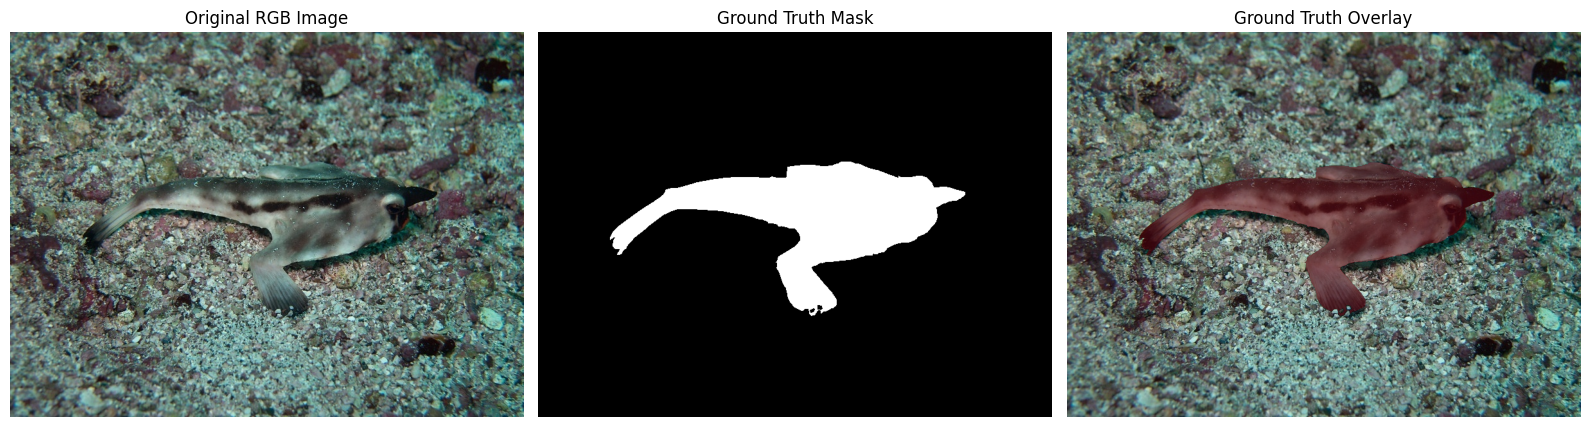

Image dimensions: (800, 600)
Mask dimensions: (800, 600)
Unique mask values: [  0 255]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

sample = dataset["train"][0]

image = sample["image"].convert("RGB")
mask = sample["mask"].convert("L")

mask_array = np.array(mask)
binary_mask = (mask_array > 127).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Original RGB Image")

axes[1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(image)
axes[2].imshow(
    np.ma.masked_where(binary_mask == 0, binary_mask),
    cmap="Reds",
    alpha=0.5,
    vmin=0,
    vmax=1
)
axes[2].set_title("Ground Truth Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Image dimensions:", image.size)
print("Mask dimensions:", mask.size)
print("Unique mask values:", np.unique(mask_array))


In [ ]:

from datasets import DatasetDict

# Reproducible 90/10 training-validation split
split = dataset["train"].train_test_split(
    test_size=0.10,
    seed=42,
    shuffle=True
)

ghostvision_data = DatasetDict({
    "train": split["train"],
    "validation": split["test"],
    "test": dataset["test"]
})

print("===== GHOSTVISION RGB SPLITS =====")

for name, data in ghostvision_data.items():
    print(f"{name}: {len(data)} images")

# Ensure we have all expected samples
assert len(ghostvision_data["train"]) == 2736
assert len(ghostvision_data["validation"]) == 304
assert len(ghostvision_data["test"]) == 2026

print("\nDataset split verification: PASSED")


===== GHOSTVISION RGB SPLITS =====
train: 2736 images
validation: 304 images
test: 2026 images

Dataset split verification: PASSED


In [ ]:

import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_SIZE = 256

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_sample(sample):
    image = sample["image"].convert("RGB")
    mask = sample["mask"].convert("L")

    # Resize image with smooth interpolation
    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    # Resize mask without introducing new labels
    mask = mask.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.NEAREST
    )

    image_array = np.asarray(image, dtype=np.float32) / 255.0
    mask_array = (
        np.asarray(mask, dtype=np.uint8) > 127
    ).astype(np.float32)

    image_normalized = (image_array - MEAN) / STD

    image_tensor = torch.from_numpy(
        image_normalized.transpose(2, 0, 1)
    ).float()

    mask_tensor = torch.from_numpy(
        mask_array[None, :, :]
    ).float()

    return image_tensor, mask_tensor

# Test with one training sample
sample = ghostvision_data["train"][0]
image_tensor, mask_tensor = preprocess_sample(sample)

print("Image tensor shape:", image_tensor.shape)
print("Mask tensor shape:", mask_tensor.shape)
print("Image dtype:", image_tensor.dtype)
print("Mask unique values:", torch.unique(mask_tensor))
print("Image finite:", torch.isfinite(image_tensor).all().item())

assert image_tensor.shape == (3, 256, 256)
assert mask_tensor.shape == (1, 256, 256)
assert set(torch.unique(mask_tensor).tolist()).issubset({0.0, 1.0})
assert torch.isfinite(image_tensor).all()

print("Preprocessing verification: PASSED")


Image tensor shape: torch.Size([3, 256, 256])
Mask tensor shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Mask unique values: tensor([0., 1.])
Image finite: True
Preprocessing verification: PASSED


In [ ]:

from torch.utils.data import Dataset, DataLoader

class GhostVisionDataset(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        return preprocess_sample(sample)

train_data = GhostVisionDataset(
    ghostvision_data["train"]
)

val_data = GhostVisionDataset(
    ghostvision_data["validation"]
)

train_loader = DataLoader(
    train_data,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, masks = next(iter(train_loader))

print("===== DATALOADER VERIFICATION =====")
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Batch images:", images.shape)
print("Batch masks:", masks.shape)

assert images.shape == (8, 3, 256, 256)
assert masks.shape == (8, 1, 256, 256)

print("DataLoader verification: PASSED")


===== DATALOADER VERIFICATION =====
Training samples: 2736
Validation samples: 304
Batch images: torch.Size([8, 3, 256, 256])
Batch masks: torch.Size([8, 1, 256, 256])
DataLoader verification: PASSED


In [ ]:

%pip install -q segmentation-models-pytorch==0.5.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.0 MB/s eta 0:00:00


In [ ]:

import torch
import segmentation_models_pytorch as smp

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

print("===== GHOSTVISION RGB MODEL =====")
print("Model: U-Net + ResNet34")
print("Device:", device)

# Test forward pass using one RGB image
model.eval()

with torch.no_grad():
    test_input = image_tensor.unsqueeze(0).to(device)
    output = model(test_input)
    probabilities = torch.sigmoid(output)

print("Input shape:", test_input.shape)
print("Output shape:", output.shape)
print("Probability range:",
      probabilities.min().item(),
      probabilities.max().item())

assert output.shape == (1, 1, 256, 256)
assert torch.isfinite(output).all()

print("Model forward-pass verification: PASSED")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

===== GHOSTVISION RGB MODEL =====
Model: U-Net + ResNet34
Device: cuda
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])
Probability range: 0.10886190831661224 0.6104910373687744
Model forward-pass verification: PASSED


In [ ]:

import torch
import torch.nn as nn

# Training configuration
LEARNING_RATE = 1e-4
EPOCHS = 20

# Binary Cross Entropy loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice loss for segmentation
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    probs = probs.flatten(1)
    targets = targets.flatten(1)

    intersection = (probs * targets).sum(dim=1)
    total = probs.sum(dim=1) + targets.sum(dim=1)

    dice = (2 * intersection + smooth) / (
        total + smooth
    )

    return 1 - dice.mean()

# Combined segmentation loss
def combined_loss(logits, targets):
    return (
        bce_loss(logits, targets)
        + dice_loss(logits, targets)
    )

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# Verify loss calculation on one real batch
batch_images, batch_masks = next(iter(train_loader))

batch_images = batch_images.to(device)
batch_masks = batch_masks.to(device)

model.train()
optimizer.zero_grad(set_to_none=True)

batch_logits = model(batch_images)
loss = combined_loss(batch_logits, batch_masks)

print("===== GHOSTVISION TRAINING SETUP =====")
print("Model: U-Net + ResNet34")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Planned epochs:", EPOCHS)
print("Batch shape:", batch_logits.shape)
print("Initial loss:", loss.item())

assert torch.isfinite(loss).item()
assert batch_logits.shape == batch_masks.shape

print("Training configuration: PASSED")


===== GHOSTVISION TRAINING SETUP =====
Model: U-Net + ResNet34
Optimizer: AdamW
Learning rate: 0.0001
Planned epochs: 20
Batch shape: torch.Size([8, 1, 256, 256])
Initial loss: 1.4504194259643555
Training configuration: PASSED


In [ ]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Create persistent checkpoint folder
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "best_rgb_unet_resnet34.pth"
)

def require_output_replacement_opt_in(
    paths, allow_replacement, opt_in_name
):
    existing = [Path(path) for path in paths if Path(path).exists()]

    if existing and allow_replacement is not True:
        existing_list = "\n".join(f"- {path}" for path in existing)
        raise FileExistsError(
            "Existing output files would be replaced:\n"
            f"{existing_list}\n"
            f"Set {opt_in_name} = True only after reviewing "
            "these files and explicitly approving replacement."
        )

print("===== GHOSTVISION CHECKPOINT SETUP =====")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Best model path:", BEST_MODEL_PATH)
print("Directory exists:", CHECKPOINT_DIR.is_dir())

assert CHECKPOINT_DIR.is_dir()

print("Checkpoint storage verification: PASSED")


Mounted at /content/drive
===== GHOSTVISION CHECKPOINT SETUP =====
Checkpoint directory: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints
Best model path: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/best_rgb_unet_resnet34.pth
Directory exists: True
Checkpoint storage verification: PASSED


In [ ]:

import torch
import numpy as np
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

def calculate_metrics(logits, targets, eps=1e-7):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()

    intersection = (predictions * targets).sum(
        dim=(1, 2, 3)
    )
    pred_sum = predictions.sum(dim=(1, 2, 3))
    target_sum = targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (
        pred_sum + target_sum + eps
    )
    union = pred_sum + target_sum - intersection

    iou = (intersection + eps) / (union + eps)

    return dice.mean().item(), iou.mean().item()


def run_epoch(loader, training=True):
    model.train(training)

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0
    total_images = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = combined_loss(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        dice, iou = calculate_metrics(
            logits.detach(), masks
        )

        count = images.size(0)
        total_loss += loss.item() * count
        total_dice += dice * count
        total_iou += iou * count
        total_images += count

    return {
        "loss": total_loss / total_images,
        "dice": total_dice / total_images,
        "iou": total_iou / total_images
    }


# One-epoch pilot. Replacement is disabled by default.
PILOT_CHECKPOINT_PATH = CHECKPOINT_DIR / "rgb_pilot_epoch1.pth"
ALLOW_PILOT_CHECKPOINT_REPLACEMENT = globals().get(
    "ALLOW_PILOT_CHECKPOINT_REPLACEMENT", False
)

require_output_replacement_opt_in(
    [PILOT_CHECKPOINT_PATH],
    ALLOW_PILOT_CHECKPOINT_REPLACEMENT,
    "ALLOW_PILOT_CHECKPOINT_REPLACEMENT"
)
# Consume the opt-in so a later rerun requires fresh approval.
ALLOW_PILOT_CHECKPOINT_REPLACEMENT = False

print("===== GHOSTVISION RGB TRAINING PILOT =====")

train_results = run_epoch(train_loader, training=True)
val_results = run_epoch(val_loader, training=False)

print("Training:", train_results)
print("Validation:", val_results)

# Save an initial recoverable checkpoint
torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_metrics": train_results,
    "val_metrics": val_results,
    "architecture": "Unet-ResNet34",
    "image_size": 256,
    "seed": 42
}, PILOT_CHECKPOINT_PATH)

assert PILOT_CHECKPOINT_PATH.is_file()
assert all(np.isfinite(v) for v in val_results.values())

print("Pilot checkpoint:", PILOT_CHECKPOINT_PATH)
print("One-epoch training pilot: PASSED")


===== GHOSTVISION RGB TRAINING PILOT =====
Training: {'loss': 0.9887026151021322, 'dice': 0.44754650071263313, 'iou': 0.3249944469493906}
Validation: {'loss': 0.7962008902901098, 'dice': 0.5258019629277682, 'iou': 0.3987218031757756}
Pilot checkpoint: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/rgb_pilot_epoch1.pth
One-epoch training pilot: PASSED


In [ ]:

import torch

# Load our actual epoch-1 checkpoint
checkpoint = torch.load(
    PILOT_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# Restore trained model and optimizer
model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Make sure optimizer tensors use the correct device
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

completed_epoch = checkpoint["epoch"]
pilot_val_dice = checkpoint["val_metrics"]["dice"]

print("===== GHOSTVISION CHECKPOINT RECOVERY =====")
print("Architecture:", checkpoint["architecture"])
print("Completed epoch:", completed_epoch)
print("Saved validation Dice:", round(pilot_val_dice, 4))
print("Saved validation IoU:",
      round(checkpoint["val_metrics"]["iou"], 4))
print("Device:", device)

assert completed_epoch == 1
assert checkpoint["architecture"] == "Unet-ResNet34"
assert all(torch.isfinite(p).all() for p in model.parameters())

print("Checkpoint recovery: PASSED")
print("Ready to continue from epoch:", completed_epoch + 1)


===== GHOSTVISION CHECKPOINT RECOVERY =====
Architecture: Unet-ResNet34
Completed epoch: 1
Saved validation Dice: 0.5258
Saved validation IoU: 0.3987
Device: cuda
Checkpoint recovery: PASSED
Ready to continue from epoch: 2


In [ ]:

import torch
import numpy as np
import json
import os
from pathlib import Path

LAST_CHECKPOINT_PATH = CHECKPOINT_DIR / "last_rgb_checkpoint.pth"
HISTORY_PATH = CHECKPOINT_DIR / "rgb_training_history.json"
ALLOW_BASELINE_OUTPUT_REPLACEMENT = globals().get(
    "ALLOW_BASELINE_OUTPUT_REPLACEMENT", False
)

# Start with the verified epoch-1 pilot
history = {
    "epoch": [1],
    "train_loss": [float(checkpoint["train_metrics"]["loss"])],
    "train_dice": [float(checkpoint["train_metrics"]["dice"])],
    "train_iou": [float(checkpoint["train_metrics"]["iou"])],
    "val_loss": [float(checkpoint["val_metrics"]["loss"])],
    "val_dice": [float(checkpoint["val_metrics"]["dice"])],
    "val_iou": [float(checkpoint["val_metrics"]["iou"])]
}

best_val_dice = float(checkpoint["val_metrics"]["dice"])

# Save the pilot as the initial best model
if not BEST_MODEL_PATH.exists():
    torch.save(checkpoint, BEST_MODEL_PATH)

def save_training_checkpoint(
    epoch, train_metrics, val_metrics, replacement_authorized=False
):
    global best_val_dice

    state = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "architecture": "Unet-ResNet34",
        "image_size": IMAGE_SIZE,
        "seed": 42
    }

    is_new_best = val_metrics["dice"] > best_val_dice
    replacement_targets = [LAST_CHECKPOINT_PATH, HISTORY_PATH]
    if is_new_best:
        replacement_targets.append(BEST_MODEL_PATH)

    require_output_replacement_opt_in(
        replacement_targets,
        replacement_authorized,
        "ALLOW_BASELINE_OUTPUT_REPLACEMENT"
    )

    # Save latest completed epoch
    temp_path = CHECKPOINT_DIR / "last_rgb_checkpoint.tmp"
    torch.save(state, temp_path)
    os.replace(temp_path, LAST_CHECKPOINT_PATH)

    # Save the best validation model
    if is_new_best:
        best_val_dice = val_metrics["dice"]
        best_temp = CHECKPOINT_DIR / "best_rgb_checkpoint.tmp"
        torch.save(state, best_temp)
        os.replace(best_temp, BEST_MODEL_PATH)
        print("New best validation Dice!")

    history_temp = CHECKPOINT_DIR / "rgb_training_history.tmp"
    with open(history_temp, "w") as f:
        json.dump(history, f, indent=2)
    os.replace(history_temp, HISTORY_PATH)


def continue_training(start_epoch=2, end_epoch=20):
    global ALLOW_BASELINE_OUTPUT_REPLACEMENT

    require_output_replacement_opt_in(
        [LAST_CHECKPOINT_PATH, HISTORY_PATH, BEST_MODEL_PATH],
        ALLOW_BASELINE_OUTPUT_REPLACEMENT,
        "ALLOW_BASELINE_OUTPUT_REPLACEMENT"
    )

    # Consume the opt-in so a later rerun requires fresh approval.
    ALLOW_BASELINE_OUTPUT_REPLACEMENT = False

    for epoch in range(start_epoch, end_epoch + 1):
        print(f"\n===== EPOCH {epoch}/{end_epoch} =====")

        train_metrics = run_epoch(train_loader, training=True)
        val_metrics = run_epoch(val_loader, training=False)

        history["epoch"].append(epoch)
        history["train_loss"].append(float(train_metrics["loss"]))
        history["train_dice"].append(float(train_metrics["dice"]))
        history["train_iou"].append(float(train_metrics["iou"]))
        history["val_loss"].append(float(val_metrics["loss"]))
        history["val_dice"].append(float(val_metrics["dice"]))
        history["val_iou"].append(float(val_metrics["iou"]))

        print("Training:", train_metrics)
        print("Validation:", val_metrics)

        save_training_checkpoint(
            epoch,
            train_metrics,
            val_metrics,
            replacement_authorized=True
        )

        print("Checkpoint saved for epoch:", epoch)

print("===== GHOSTVISION RESUMABLE TRAINING =====")
print("Pilot epoch:", checkpoint["epoch"])
print("Initial best validation Dice:", round(best_val_dice, 4))
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Training functions ready: PASSED")


===== GHOSTVISION RESUMABLE TRAINING =====
Pilot epoch: 1
Initial best validation Dice: 0.5258
Checkpoint directory: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints
Training functions ready: PASSED


In [ ]:

import json
import torch

def restore_training_progress():
    global history, best_val_dice

    if LAST_CHECKPOINT_PATH.is_file():
        saved = torch.load(
            LAST_CHECKPOINT_PATH,
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(saved["model_state_dict"])
        optimizer.load_state_dict(saved["optimizer_state_dict"])

        for state in optimizer.state.values():
            for key, value in state.items():
                if torch.is_tensor(value):
                    state[key] = value.to(device)

        if not HISTORY_PATH.is_file():
            raise FileNotFoundError(
                "Latest checkpoint exists but training history is missing."
            )

        with open(HISTORY_PATH, "r") as f:
            history = json.load(f)

        assert history["epoch"][-1] == saved["epoch"]

        best_val_dice = max(history["val_dice"])

        print("Restored latest checkpoint.")
        print("Completed epoch:", saved["epoch"])
        return saved["epoch"] + 1

    # No subsequent epoch checkpoint: continue from pilot
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    best_val_dice = checkpoint["val_metrics"]["dice"]

    print("Using verified epoch-1 pilot checkpoint.")
    return 2


NEXT_EPOCH = restore_training_progress()

print("===== GHOSTVISION RESUME VERIFICATION =====")
print("Next training epoch:", NEXT_EPOCH)
print("Best validation Dice:", round(best_val_dice, 4))

assert 2 <= NEXT_EPOCH <= EPOCHS + 1

print("Training resume verification: PASSED")


Using verified epoch-1 pilot checkpoint.
===== GHOSTVISION RESUME VERIFICATION =====
Next training epoch: 2
Best validation Dice: 0.5258
Training resume verification: PASSED


In [ ]:

# GhostVision RGB — Controlled epoch-2 training

assert NEXT_EPOCH == 2, (
    f"Expected epoch 2, but next epoch is {NEXT_EPOCH}. "
    "Do not repeat an already completed epoch."
)

print("Starting GhostVision RGB epoch 2...")

continue_training(
    start_epoch=NEXT_EPOCH,
    end_epoch=2
)

# Verify the newly saved checkpoint
saved = torch.load(
    LAST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

with open(HISTORY_PATH, "r") as f:
    saved_history = json.load(f)

assert saved["epoch"] == 2
assert saved_history["epoch"] == [1, 2]
assert BEST_MODEL_PATH.is_file()

print("\n===== EPOCH 2 VERIFICATION =====")
print("Saved epoch:", saved["epoch"])
print("Validation Dice:", saved["val_metrics"]["dice"])
print("Validation IoU:", saved["val_metrics"]["iou"])
print("History epochs:", saved_history["epoch"])
print("Latest checkpoint:", LAST_CHECKPOINT_PATH)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Epoch 2 checkpoint verification: PASSED")


Starting GhostVision RGB epoch 2...

===== EPOCH 2/2 =====
Training: {'loss': 0.690002852887438, 'dice': 0.580810136003801, 'iou': 0.45220930957131916}
Validation: {'loss': 0.699260801076889, 'dice': 0.541620292945912, 'iou': 0.4203449472000724}
New best validation Dice!
Checkpoint saved for epoch: 2

===== EPOCH 2 VERIFICATION =====
Saved epoch: 2
Validation Dice: 0.541620292945912
Validation IoU: 0.4203449472000724
History epochs: [1, 2]
Latest checkpoint: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/last_rgb_checkpoint.pth
Best checkpoint: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/best_rgb_unet_resnet34.pth
Epoch 2 checkpoint verification: PASSED


In [ ]:

# STEP 26 — Safe training continuation

import json
import torch
import numpy as np

# Verify saved files exist
assert LAST_CHECKPOINT_PATH.is_file(), \
    "Latest checkpoint not found!"

assert HISTORY_PATH.is_file(), \
    "Training history not found!"

# Restore latest model and optimizer
saved = torch.load(
    LAST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

assert saved["architecture"] == "Unet-ResNet34"
assert saved["image_size"] == 256

model.load_state_dict(saved["model_state_dict"])
optimizer.load_state_dict(saved["optimizer_state_dict"])

# Move optimizer state to GPU
for state in optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

# Restore complete training history
with open(HISTORY_PATH, "r") as f:
    history = json.load(f)

completed_epoch = int(saved["epoch"])

assert history["epoch"][-1] == completed_epoch
assert len(history["epoch"]) == len(
    set(history["epoch"])
), "Duplicate epochs detected!"

best_val_dice = max(history["val_dice"])
NEXT_EPOCH = completed_epoch + 1

print("===== GHOSTVISION RESUME STATUS =====")
print("Last completed epoch:", completed_epoch)
print("Next epoch:", NEXT_EPOCH)
print("Saved history:", history["epoch"])
print("Best validation Dice:", round(best_val_dice, 4))
print("GPU:", device)

assert NEXT_EPOCH == 3, \
    "Unexpected epoch! Stop and inspect."

print("Resume verification: PASSED")


===== GHOSTVISION RESUME STATUS =====
Last completed epoch: 2
Next epoch: 3
Saved history: [1, 2]
Best validation Dice: 0.5416
GPU: cuda
Resume verification: PASSED


In [ ]:

# STEP 27 — Continue RGB training safely

assert NEXT_EPOCH == 3, (
    f"Unexpected starting epoch: {NEXT_EPOCH}"
)

print("===== GHOSTVISION RGB TRAINING =====")
print("Starting epoch:", NEXT_EPOCH)
print("Training through epoch: 5")

continue_training(
    start_epoch=NEXT_EPOCH,
    end_epoch=5
)

# Verify checkpoint and history
saved = torch.load(
    LAST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

with open(HISTORY_PATH, "r") as f:
    saved_history = json.load(f)

assert saved["epoch"] == 5
assert saved_history["epoch"] == [1, 2, 3, 4, 5]
assert BEST_MODEL_PATH.is_file()

print("\n===== TRAINING VERIFICATION =====")
print("Completed epoch:", saved["epoch"])
print("History:", saved_history["epoch"])
print("Best validation Dice:",
      round(max(saved_history["val_dice"]), 4))
print("Training continuation: PASSED")


===== GHOSTVISION RGB TRAINING =====
Starting epoch: 3
Training through epoch: 5

===== EPOCH 3/5 =====
Training: {'loss': 0.5677089432352468, 'dice': 0.640606581467634, 'iou': 0.5127124138917142}
Validation: {'loss': 0.6650701510278803, 'dice': 0.5641250492710816, 'iou': 0.442964211890572}
New best validation Dice!
Checkpoint saved for epoch: 3

===== EPOCH 4/5 =====
Training: {'loss': 0.4990221280277821, 'dice': 0.6778292296922694, 'iou': 0.553089984066305}
Validation: {'loss': 0.6737331018636101, 'dice': 0.554612851456592, 'iou': 0.43836971725288193}
Checkpoint saved for epoch: 4

===== EPOCH 5/5 =====
Training: {'loss': 0.44913948540799103, 'dice': 0.7075442344995967, 'iou': 0.585236284729333}
Validation: {'loss': 0.7115609261550402, 'dice': 0.5342035262208236, 'iou': 0.42045954654091283}
Checkpoint saved for epoch: 5

===== TRAINING VERIFICATION =====
Completed epoch: 5
History: [1, 2, 3, 4, 5]
Best validation Dice: 0.5641
Training continuation: PASSED


===== GHOSTVISION TRAINING ANALYSIS =====
Completed epochs: [1, 2, 3, 4, 5]


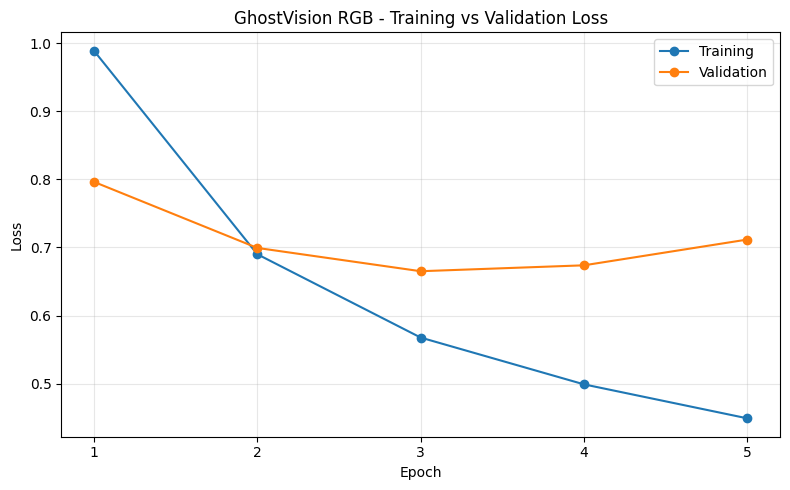

Saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/graphs/loss_curve.png


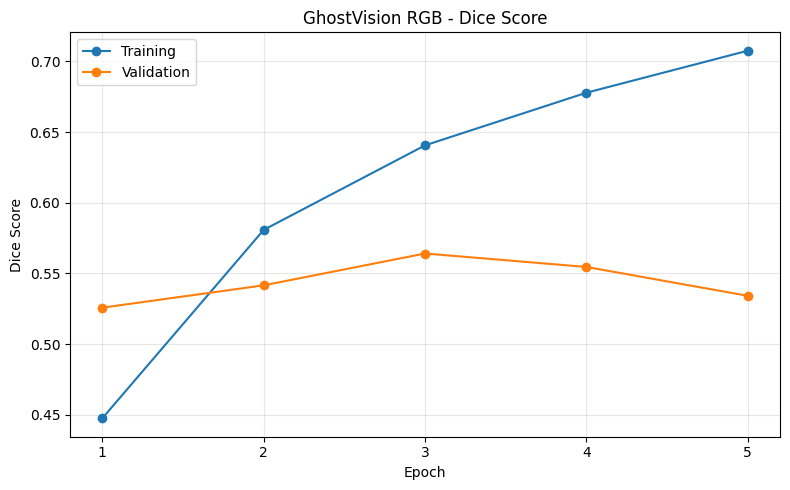

Saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/graphs/dice_curve.png


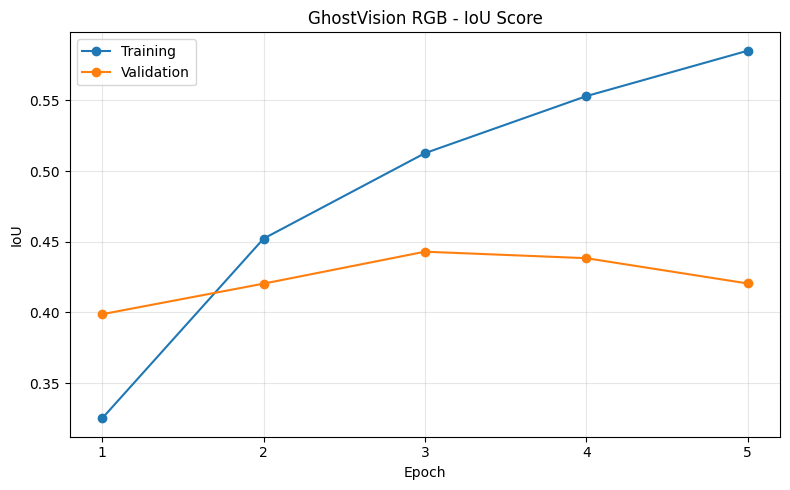

Saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/graphs/iou_curve.png

===== BEST VALIDATION RESULT =====
Best epoch: 3
Validation Dice: 0.5641250492710816
Validation IoU: 0.442964211890572
Graph generation: PASSED


In [ ]:

import json
import matplotlib.pyplot as plt
from pathlib import Path

# Load actual saved training results
with open(HISTORY_PATH, "r") as f:
    history = json.load(f)

epochs = history["epoch"]

assert len(epochs) >= 5
assert all(len(history[k]) == len(epochs) for k in [
    "train_loss", "val_loss",
    "train_dice", "val_dice",
    "train_iou", "val_iou"
])

print("===== GHOSTVISION TRAINING ANALYSIS =====")
print("Completed epochs:", epochs)

GRAPH_DIR = CHECKPOINT_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

def plot_metric(train_key, val_key, title, ylabel, filename):
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs, history[train_key],
        marker="o", label="Training"
    )

    plt.plot(
        epochs, history[val_key],
        marker="o", label="Validation"
    )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.xticks(epochs)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    save_path = GRAPH_DIR / filename
    plt.savefig(save_path, dpi=200)
    plt.show()
    plt.close()

    print("Saved:", save_path)

plot_metric(
    "train_loss", "val_loss",
    "GhostVision RGB - Training vs Validation Loss",
    "Loss",
    "loss_curve.png"
)

plot_metric(
    "train_dice", "val_dice",
    "GhostVision RGB - Dice Score",
    "Dice Score",
    "dice_curve.png"
)

plot_metric(
    "train_iou", "val_iou",
    "GhostVision RGB - IoU Score",
    "IoU",
    "iou_curve.png"
)

best_idx = max(
    range(len(history["val_dice"])),
    key=lambda i: history["val_dice"][i]
)

print("\n===== BEST VALIDATION RESULT =====")
print("Best epoch:", epochs[best_idx])
print("Validation Dice:", history["val_dice"][best_idx])
print("Validation IoU:", history["val_iou"][best_idx])
print("Graph generation: PASSED")


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader
import random

# Reproducibility for the new experiment
AUG_SEED = 42
random.seed(AUG_SEED)
torch.manual_seed(AUG_SEED)

class AugmentedGhostVisionDataset(Dataset):
    def __init__(self, hf_dataset, augment=False):
        self.data = hf_dataset
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image, mask = preprocess_sample(self.data[idx])

        if self.augment:
            # Horizontal flip
            if random.random() < 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])

            # Vertical flip
            if random.random() < 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[1])

        return image.contiguous(), mask.contiguous()


# Use augmentation only for training
aug_train_data = AugmentedGhostVisionDataset(
    ghostvision_data["train"],
    augment=True
)

# Validation remains unchanged
aug_val_data = AugmentedGhostVisionDataset(
    ghostvision_data["validation"],
    augment=False
)

aug_train_loader = DataLoader(
    aug_train_data,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

aug_val_loader = DataLoader(
    aug_val_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify batch dimensions
aug_images, aug_masks = next(iter(aug_train_loader))

assert aug_images.shape == (8, 3, 256, 256)
assert aug_masks.shape == (8, 1, 256, 256)
assert torch.isfinite(aug_images).all()
assert set(torch.unique(aug_masks).tolist()).issubset({0.0, 1.0})

print("===== GHOSTVISION AUGMENTATION =====")
print("Training samples:", len(aug_train_data))
print("Validation samples:", len(aug_val_data))
print("Training augmentation: Enabled")
print("Validation augmentation: Disabled")
print("Image batch:", aug_images.shape)
print("Mask batch:", aug_masks.shape)
print("Augmentation DataLoader: PASSED")


===== GHOSTVISION AUGMENTATION =====
Training samples: 2736
Validation samples: 304
Training augmentation: Enabled
Validation augmentation: Disabled
Image batch: torch.Size([8, 3, 256, 256])
Mask batch: torch.Size([8, 1, 256, 256])
Augmentation DataLoader: PASSED


In [ ]:

import torch
import segmentation_models_pytorch as smp
from pathlib import Path

# Create separate experiment directory
AUG_DIR = CHECKPOINT_DIR / "Augmented_Experiment"
AUG_DIR.mkdir(parents=True, exist_ok=True)

AUG_BEST_PATH = AUG_DIR / "best_augmented_unet.pth"
AUG_LAST_PATH = AUG_DIR / "last_augmented_unet.pth"

# Initialize a NEW model, preserving the baseline
torch.manual_seed(42)

aug_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

aug_optimizer = torch.optim.AdamW(
    aug_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Verify model with an augmented batch
aug_model.eval()

with torch.no_grad():
    inputs = aug_images[:2].to(device)
    outputs = aug_model(inputs)

assert outputs.shape == (2, 1, 256, 256)
assert torch.isfinite(outputs).all()

print("===== GHOSTVISION AUGMENTED MODEL =====")
print("Architecture: U-Net + ResNet34")
print("Device:", device)
print("Input shape:", inputs.shape)
print("Output shape:", outputs.shape)
print("Experiment directory:", AUG_DIR)
print("Baseline checkpoint exists:", BEST_MODEL_PATH.is_file())
print("Augmented model verification: PASSED")


===== GHOSTVISION AUGMENTED MODEL =====
Architecture: U-Net + ResNet34
Device: cuda
Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])
Experiment directory: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Augmented_Experiment
Baseline checkpoint exists: True
Augmented model verification: PASSED


In [ ]:

import torch
import json
import os
import numpy as np

AUG_HISTORY_PATH = AUG_DIR / "augmented_history.json"

# Prevent accidental replacement of any augmented output.
ALLOW_AUGMENTED_OUTPUT_REPLACEMENT = globals().get(
    "ALLOW_AUGMENTED_OUTPUT_REPLACEMENT", False
)
require_output_replacement_opt_in(
    [AUG_LAST_PATH, AUG_BEST_PATH, AUG_HISTORY_PATH],
    ALLOW_AUGMENTED_OUTPUT_REPLACEMENT,
    "ALLOW_AUGMENTED_OUTPUT_REPLACEMENT"
)
# Consume the opt-in so a later rerun requires fresh approval.
ALLOW_AUGMENTED_OUTPUT_REPLACEMENT = False

aug_history = {
    "epoch": [],
    "train_loss": [],
    "train_dice": [],
    "train_iou": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

aug_best_dice = -1.0

def run_aug_epoch(loader, training):
    aug_model.train(training)

    totals = {"loss": 0.0, "dice": 0.0, "iou": 0.0}
    count = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        if training:
            aug_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = aug_model(images)
            loss = combined_loss(logits, masks)

            if training:
                loss.backward()
                aug_optimizer.step()

        dice, iou = calculate_metrics(logits.detach(), masks)
        n = images.size(0)

        totals["loss"] += loss.item() * n
        totals["dice"] += dice * n
        totals["iou"] += iou * n
        count += n

    return {key: value / count for key, value in totals.items()}


def save_aug_checkpoint(epoch, train_result, val_result):
    global aug_best_dice

    state = {
        "epoch": epoch,
        "model_state_dict": aug_model.state_dict(),
        "optimizer_state_dict": aug_optimizer.state_dict(),
        "train_metrics": train_result,
        "val_metrics": val_result,
        "architecture": "Unet-ResNet34",
        "augmentation": "horizontal_vertical_flip",
        "seed": 42
    }

    tmp = AUG_DIR / "augmented_latest.tmp"
    torch.save(state, tmp)
    os.replace(tmp, AUG_LAST_PATH)

    if val_result["dice"] > aug_best_dice:
        aug_best_dice = val_result["dice"]
        tmp_best = AUG_DIR / "augmented_best.tmp"
        torch.save(state, tmp_best)
        os.replace(tmp_best, AUG_BEST_PATH)

    tmp_history = AUG_DIR / "augmented_history.tmp"
    with open(tmp_history, "w") as f:
        json.dump(aug_history, f, indent=2)
    os.replace(tmp_history, AUG_HISTORY_PATH)


print("===== AUGMENTED TRAINING =====")

for epoch in range(1, 6):
    train_result = run_aug_epoch(aug_train_loader, True)
    val_result = run_aug_epoch(aug_val_loader, False)

    for prefix, values in [
        ("train", train_result),
        ("val", val_result)
    ]:
        for metric, value in values.items():
            aug_history[f"{prefix}_{metric}"].append(float(value))

    aug_history["epoch"].append(epoch)

    print(f"Epoch {epoch}/5")
    print("Training:", train_result)
    print("Validation:", val_result)

    save_aug_checkpoint(epoch, train_result, val_result)

assert AUG_LAST_PATH.is_file()
assert AUG_BEST_PATH.is_file()
assert AUG_HISTORY_PATH.is_file()
assert aug_history["epoch"] == [1, 2, 3, 4, 5]

print("\nBest augmented validation Dice:", round(aug_best_dice, 4))
print("Augmented training verification: PASSED")


===== AUGMENTED TRAINING =====
Epoch 1/5
Training: {'loss': 1.1661293738418155, 'dice': 0.40907115271391226, 'iou': 0.28902344578844413}
Validation: {'loss': 0.9269428613938784, 'dice': 0.49429377482125636, 'iou': 0.36868248095637873}
Epoch 2/5
Training: {'loss': 0.8406068965008384, 'dice': 0.5197954754731808, 'iou': 0.3927754650861896}
Validation: {'loss': 0.7723663888479534, 'dice': 0.5255764989476455, 'iou': 0.3991866198025252}
Epoch 3/5
Training: {'loss': 0.7151452868479734, 'dice': 0.5560033912198585, 'iou': 0.4293944632623628}
Validation: {'loss': 0.7034100200000563, 'dice': 0.5418236616410708, 'iou': 0.41969261632153865}
Epoch 4/5
Training: {'loss': 0.6533387478506356, 'dice': 0.5815077822285089, 'iou': 0.45480789231103763}
Validation: {'loss': 0.7065323206939196, 'dice': 0.5339797241123099, 'iou': 0.4126298309941041}
Epoch 5/5
Training: {'loss': 0.621550348157074, 'dice': 0.5966762126537791, 'iou': 0.47095746991404314}
Validation: {'loss': 0.6855048772535826, 'dice': 0.54473903

In [ ]:

from google.colab import drive
from pathlib import Path
import json
import torch

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints")
AUG_DIR = ROOT / "Augmented_Experiment"

files = [
    ROOT / "best_rgb_unet_resnet34.pth",
    AUG_DIR / "last_augmented_unet.pth",
    AUG_DIR / "best_augmented_unet.pth",
    AUG_DIR / "augmented_history.json",
]

print("===== GHOSTVISION CHECKPOINT AUDIT =====")

for path in files:
    exists = path.is_file()
    print(f"{path.name}: {'FOUND' if exists else 'MISSING'}")
    if exists:
        print(f"  Size: {path.stat().st_size / (1024**2):.2f} MB")

history_path = AUG_DIR / "augmented_history.json"

if history_path.is_file():
    with open(history_path) as f:
        history = json.load(f)

    print("\nRecorded epochs:", history.get("epoch"))
    print("Validation Dice:", history.get("val_dice"))
    print("Validation IoU:", history.get("val_iou"))

best_path = AUG_DIR / "best_augmented_unet.pth"

if best_path.is_file():
    checkpoint = torch.load(
        best_path, map_location="cpu", weights_only=True
    )
    print("\nBest checkpoint epoch:", checkpoint["epoch"])
    print("Best checkpoint validation metrics:",
          checkpoint["val_metrics"])

print("\nCheckpoint audit finished.")


Mounted at /content/drive
===== GHOSTVISION CHECKPOINT AUDIT =====
best_rgb_unet_resnet34.pth: FOUND
  Size: 279.94 MB
last_augmented_unet.pth: FOUND
  Size: 279.94 MB
best_augmented_unet.pth: FOUND
  Size: 279.94 MB
augmented_history.json: FOUND
  Size: 0.00 MB

Recorded epochs: [1, 2, 3, 4, 5]
Validation Dice: [0.49429377482125636, 0.5255764989476455, 0.5418236616410708, 0.5339797241123099, 0.5447390306937067]
Validation IoU: [0.36868248095637873, 0.3991866198025252, 0.41969261632153865, 0.4126298309941041, 0.4283105805516243]

Best checkpoint epoch: 5
Best checkpoint validation metrics: {'loss': 0.6855048772535826, 'dice': 0.5447390306937067, 'iou': 0.4283105805516243}

Checkpoint audit finished.


In [ ]:

from pathlib import Path
import torch

ROOT = Path("/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints")
AUG_DIR = ROOT / "Augmented_Experiment"

print("===== GHOSTVISION TEST EVALUATION PREFLIGHT =====")
print("GPU available:", torch.cuda.is_available())
print("Baseline checkpoint:", (ROOT / "best_rgb_unet_resnet34.pth").is_file())
print("Augmented checkpoint:", (AUG_DIR / "best_augmented_unet.pth").is_file())

required = [
    "dataset",
    "ghostvision_data",
    "preprocess_sample",
    "calculate_metrics",
    "device"
]

print("\nRuntime variables:")
for name in required:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

if "ghostvision_data" in globals():
    print("\nDataset splits:")
    for name, split in ghostvision_data.items():
        print(f"{name}: {len(split)} images")

print("\nPreflight complete. No training performed.")


===== GHOSTVISION TEST EVALUATION PREFLIGHT =====
GPU available: True
Baseline checkpoint: True
Augmented checkpoint: True

Runtime variables:
dataset: MISSING
ghostvision_data: MISSING
preprocess_sample: MISSING
calculate_metrics: MISSING
device: MISSING

Preflight complete. No training performed.


In [ ]:

from datasets import load_dataset, DatasetDict

print("===== RESTORING COD10K DATASET =====")

# Load the same dataset used for training
dataset = load_dataset("nobg/COD10K")

# Verify the original dataset sizes
assert len(dataset["train"]) == 3040
assert len(dataset["test"]) == 2026

# Recreate the exact deterministic training/validation split
train_val_split = dataset["train"].train_test_split(
    test_size=0.10,
    seed=42,
    shuffle=True
)

ghostvision_data = DatasetDict({
    "train": train_val_split["train"],
    "validation": train_val_split["test"],
    "test": dataset["test"]
})

# Verify all splits
print("\n===== SPLIT VERIFICATION =====")
for name, split_data in ghostvision_data.items():
    print(f"{name}: {len(split_data)} images")

assert len(ghostvision_data["train"]) == 2736
assert len(ghostvision_data["validation"]) == 304
assert len(ghostvision_data["test"]) == 2026

print("\nDataset restoration: PASSED")
print("Original split verification: PASSED")
print("Test set remains separate from training and validation.")


===== RESTORING COD10K DATASET =====


README.md:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  454MB            

...

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  297MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3040 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2026 [00:00<?, ? examples/s]


===== SPLIT VERIFICATION =====
train: 2736 images
validation: 304 images
test: 2026 images

Dataset restoration: PASSED
Original split verification: PASSED
Test set remains separate from training and validation.


In [ ]:

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

IMAGE_SIZE = 256
BATCH_SIZE = 8

# ImageNet normalization used by the pretrained ResNet34 encoder
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def preprocess_sample(sample):
    # Resize RGB image
    image = sample["image"].convert("RGB")
    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.BILINEAR
    )

    # Resize segmentation mask without smoothing its boundaries
    mask = sample["mask"].convert("L")
    mask = mask.resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Resampling.NEAREST
    )

    image_array = np.asarray(image, dtype=np.float32) / 255.0
    mask_array = np.asarray(mask, dtype=np.uint8)

    # Normalize image channels
    image_array = (image_array - IMAGENET_MEAN) / IMAGENET_STD

    # Convert RGB HWC -> CHW
    image_tensor = torch.from_numpy(
        image_array.transpose(2, 0, 1).copy()
    ).float()

    # Convert mask to binary foreground/background
    mask_array = (mask_array > 127).astype(np.float32)
    mask_tensor = torch.from_numpy(mask_array[None, :, :]).float()

    return image_tensor, mask_tensor


class GhostVisionDataset(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return preprocess_sample(self.data[index])


# Restore training and validation datasets
train_data = GhostVisionDataset(ghostvision_data["train"])
val_data = GhostVisionDataset(ghostvision_data["validation"])

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Verify a complete batch
images, masks = next(iter(train_loader))

print("===== GHOSTVISION PREPROCESSING =====")
print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image values finite:", torch.isfinite(images).all().item())
print("Mask values:", torch.unique(masks).tolist())

assert images.shape == (8, 3, 256, 256)
assert masks.shape == (8, 1, 256, 256)
assert torch.isfinite(images).all()
assert set(torch.unique(masks).tolist()).issubset({0.0, 1.0})

print("Preprocessing verification: PASSED")


===== GHOSTVISION PREPROCESSING =====
Training samples: 2736
Validation samples: 304
Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image values finite: True
Mask values: [0.0, 1.0]
Preprocessing verification: PASSED


In [ ]:

from pathlib import Path
import torch
import gc

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints"
)

CHECKPOINTS = {
    "Baseline": CHECKPOINT_DIR / "best_rgb_unet_resnet34.pth",
    "Augmented": (
        CHECKPOINT_DIR
        / "Augmented_Experiment"
        / "best_augmented_unet.pth"
    ),
}

print("===== GHOSTVISION CHECKPOINT AUDIT =====")

for name, path in CHECKPOINTS.items():
    print(f"\n{name} checkpoint:")
    print("Path:", path)
    print("Exists:", path.is_file())

    if not path.is_file():
        print("CHECKPOINT MISSING")
        continue

    print("Size (MB):", round(path.stat().st_size / (1024**2), 2))

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Saved object type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Saved keys:", list(checkpoint.keys()))
        print("Architecture:", checkpoint.get("architecture", "Not recorded"))
        print("Epoch:", checkpoint.get("epoch", "Not recorded"))
        print("Image size:", checkpoint.get("image_size", "Not recorded"))

        for key in ("val_metrics", "validation_metrics"):
            if key in checkpoint:
                print("Validation metrics:", checkpoint[key])
                break

        state = checkpoint.get("model_state_dict")

        if isinstance(state, dict):
            print("Model parameter tensors:", len(state))
            print("First parameter names:", list(state.keys())[:5])
        else:
            print("Model state dict not found under model_state_dict.")

    del checkpoint
    gc.collect()

print("\nCheckpoint audit complete.")


===== GHOSTVISION CHECKPOINT AUDIT =====

Baseline checkpoint:
Path: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/best_rgb_unet_resnet34.pth
Exists: True
Size (MB): 279.94
Saved object type: dict
Saved keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_metrics', 'val_metrics', 'architecture', 'image_size', 'seed']
Architecture: Unet-ResNet34
Epoch: 3
Image size: 256
Validation metrics: {'loss': 0.6650701510278803, 'dice': 0.5641250492710816, 'iou': 0.442964211890572}
Model parameter tensors: 278
First parameter names: ['encoder.conv1.weight', 'encoder.bn1.weight', 'encoder.bn1.bias', 'encoder.bn1.running_mean', 'encoder.bn1.running_var']

Augmented checkpoint:
Path: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Augmented_Experiment/best_augmented_unet.pth
Exists: True
Size (MB): 279.94
Saved object type: dict
Saved keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_metrics', 'val_metrics', 'architecture', 'augmentation', 'seed']
Architec

In [ ]:

%pip install -q segmentation-models-pytorch


In [ ]:

import segmentation_models_pytorch as smp
import torch

print("Segmentation Models PyTorch:", smp.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

print("Dependency verification: PASSED")


Segmentation Models PyTorch: 0.5.0
CUDA available: True
Device: cuda
Dependency verification: PASSED


In [ ]:

import torch
import segmentation_models_pytorch as smp
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints"
)

checkpoint_paths = {
    "Baseline": CHECKPOINT_DIR / "best_rgb_unet_resnet34.pth",
    "Augmented": (
        CHECKPOINT_DIR
        / "Augmented_Experiment"
        / "best_augmented_unet.pth"
    ),
}


def restore_model(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(device)
    model.eval()

    return model, checkpoint


models = {}
checkpoints = {}

for name, path in checkpoint_paths.items():
    assert path.is_file(), f"Missing checkpoint: {path}"

    models[name], checkpoints[name] = restore_model(path)

    print(f"{name} model restored successfully")
    print("Saved epoch:", checkpoints[name]["epoch"])
    print("Saved validation Dice:",
          round(checkpoints[name]["val_metrics"]["dice"], 4))
    print("Saved validation IoU:",
          round(checkpoints[name]["val_metrics"]["iou"], 4))


# Verify both models produce valid segmentation outputs
test_images = images[:2].to(device)

with torch.no_grad():
    for name, model in models.items():
        logits = model(test_images)

        print(f"\n{name} forward-pass verification")
        print("Output shape:", tuple(logits.shape))
        print("All outputs finite:", torch.isfinite(logits).all().item())

        assert logits.shape == (2, 1, 256, 256)
        assert torch.isfinite(logits).all()

        del logits

print("\nMODEL RESTORATION VERIFICATION: PASSED")
print("Device:", device)


Baseline model restored successfully
Saved epoch: 3
Saved validation Dice: 0.5641
Saved validation IoU: 0.443
Augmented model restored successfully
Saved epoch: 5
Saved validation Dice: 0.5447
Saved validation IoU: 0.4283

Baseline forward-pass verification
Output shape: (2, 1, 256, 256)
All outputs finite: True

Augmented forward-pass verification
Output shape: (2, 1, 256, 256)
All outputs finite: True

MODEL RESTORATION VERIFICATION: PASSED
Device: cuda


In [ ]:

import torch

EPS = 1e-7
results = {}

for name, model in models.items():
    model.eval()

    total_dice = 0.0
    total_iou = 0.0
    total_images = 0

    with torch.inference_mode():
        for val_images, val_masks in val_loader:
            val_images = val_images.to(device)
            val_masks = val_masks.to(device)

            logits = model(val_images)
            predictions = (torch.sigmoid(logits) >= 0.5).float()

            assert torch.isfinite(logits).all()

            # Calculate metrics separately for each image
            predictions = predictions.flatten(start_dim=1)
            targets = val_masks.flatten(start_dim=1)

            intersection = (predictions * targets).sum(dim=1)
            pred_area = predictions.sum(dim=1)
            target_area = targets.sum(dim=1)

            dice = (
                2 * intersection + EPS
            ) / (
                pred_area + target_area + EPS
            )

            union = pred_area + target_area - intersection
            iou = (intersection + EPS) / (union + EPS)

            total_dice += dice.sum().item()
            total_iou += iou.sum().item()
            total_images += val_images.size(0)

    assert total_images == 304

    results[name] = {
        "dice": total_dice / total_images,
        "iou": total_iou / total_images,
        "images": total_images
    }

print("===== GHOSTVISION VALIDATION COMPARISON =====")

for name, metrics in results.items():
    print(f"\n{name}")
    print("Images evaluated:", metrics["images"])
    print("Mean Dice:", round(metrics["dice"], 4))
    print("Mean IoU:", round(metrics["iou"], 4))

print("\n===== AUGMENTED MINUS BASELINE =====")
print(
    "Dice difference:",
    round(results["Augmented"]["dice"] - results["Baseline"]["dice"], 4)
)
print(
    "IoU difference:",
    round(results["Augmented"]["iou"] - results["Baseline"]["iou"], 4)
)

print("\nValidation comparison verification: PASSED")
print("Held-out test set: NOT USED")


===== GHOSTVISION VALIDATION COMPARISON =====

Baseline
Images evaluated: 304
Mean Dice: 0.5641
Mean IoU: 0.443

Augmented
Images evaluated: 304
Mean Dice: 0.5447
Mean IoU: 0.4283

===== AUGMENTED MINUS BASELINE =====
Dice difference: -0.0194
IoU difference: -0.0147

Validation comparison verification: PASSED
Held-out test set: NOT USED


In [ ]:

# GHOSTVISION AI — FINAL RGB TEST EVALUATION
# Do not use these results to tune model parameters.

import torch
from torch.utils.data import DataLoader

EPS = 1e-7

test_data = GhostVisionDataset(ghostvision_data["test"])

test_loader = DataLoader(
    test_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

assert len(test_data) == 2026

test_results = {}

for name, model in models.items():
    model.eval()

    totals = {
        "dice": 0.0,
        "iou": 0.0,
        "precision": 0.0,
        "recall": 0.0
    }

    count = 0

    with torch.inference_mode():
        for test_images, test_masks in test_loader:
            test_images = test_images.to(device)
            test_masks = test_masks.to(device)

            logits = model(test_images)
            assert torch.isfinite(logits).all()

            predictions = (
                torch.sigmoid(logits) >= 0.5
            ).float()

            # Calculate metrics separately for each image
            predictions = predictions.flatten(start_dim=1)
            targets = test_masks.flatten(start_dim=1)

            tp = (predictions * targets).sum(dim=1)
            fp = (predictions * (1 - targets)).sum(dim=1)
            fn = ((1 - predictions) * targets).sum(dim=1)

            dice = (2 * tp + EPS) / (
                2 * tp + fp + fn + EPS
            )

            iou = (tp + EPS) / (
                tp + fp + fn + EPS
            )

            precision = (tp + EPS) / (tp + fp + EPS)
            recall = (tp + EPS) / (tp + fn + EPS)

            batch_size = test_images.size(0)

            totals["dice"] += dice.sum().item()
            totals["iou"] += iou.sum().item()
            totals["precision"] += precision.sum().item()
            totals["recall"] += recall.sum().item()

            count += batch_size

    assert count == 2026

    test_results[name] = {
        metric: value / count
        for metric, value in totals.items()
    }

    test_results[name]["images"] = count

    print(f"\n===== {name.upper()} TEST RESULTS =====")
    print("Images evaluated:", count)

    for metric in ("dice", "iou", "precision", "recall"):
        print(f"Mean {metric.title()}: "
              f"{test_results[name][metric]:.4f}")

print("\n===== FINAL TEST COMPARISON =====")

for metric in ("dice", "iou", "precision", "recall"):
    difference = (
        test_results["Augmented"][metric]
        - test_results["Baseline"][metric]
    )
    print(f"Augmented - Baseline {metric}: {difference:+.4f}")

print("\nTest-set evaluation verification: PASSED")
print("Test images evaluated per model:", 2026)
print("Test set used for tuning: NO")



===== BASELINE TEST RESULTS =====
Images evaluated: 2026
Mean Dice: 0.5624
Mean Iou: 0.4392
Mean Precision: 0.5869
Mean Recall: 0.6520

===== AUGMENTED TEST RESULTS =====
Images evaluated: 2026
Mean Dice: 0.5574
Mean Iou: 0.4360
Mean Precision: 0.6215
Mean Recall: 0.6145

===== FINAL TEST COMPARISON =====
Augmented - Baseline dice: -0.0050
Augmented - Baseline iou: -0.0033
Augmented - Baseline precision: +0.0347
Augmented - Baseline recall: -0.0375

Test-set evaluation verification: PASSED
Test images evaluated per model: 2026
Test set used for tuning: NO


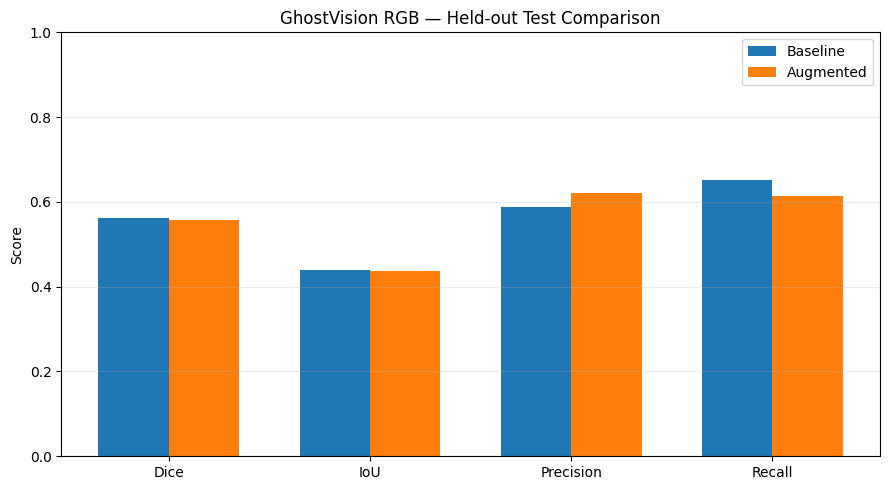


Final results saved successfully.
Output directory: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Final_Evaluation
Files: final_test_metrics.json, final_test_metrics.csv,
       final_test_comparison.png


In [ ]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Ensure Google Drive is available
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

RESULTS_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Transcribed from the verified test-evaluation output
results = {
    "Baseline": {
        "images_evaluated": 2026,
        "dice": 0.5624,
        "iou": 0.4392,
        "precision": 0.5869,
        "recall": 0.6520
    },
    "Augmented": {
        "images_evaluated": 2026,
        "dice": 0.5574,
        "iou": 0.4360,
        "precision": 0.6215,
        "recall": 0.6145
    }
}

# Save machine-readable results
with open(RESULTS_DIR / "final_test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

df = pd.DataFrame.from_dict(results, orient="index")
df.index.name = "model"
df.to_csv(RESULTS_DIR / "final_test_metrics.csv")

# Generate comparison chart
metrics = ["dice", "iou", "precision", "recall"]
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - width / 2,
       [results["Baseline"][m] for m in metrics],
       width, label="Baseline")

ax.bar(x + width / 2,
       [results["Augmented"][m] for m in metrics],
       width, label="Augmented")

ax.set_xticks(x)
ax.set_xticklabels(["Dice", "IoU", "Precision", "Recall"])
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("GhostVision RGB — Held-out Test Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "final_test_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nFinal results saved successfully.")
print("Output directory:", RESULTS_DIR)
print("Files: final_test_metrics.json, final_test_metrics.csv,")
print("       final_test_comparison.png")


In [ ]:

# GhostVision RGB: qualitative evaluation preflight

print("===== GHOSTVISION VISUAL EVALUATION PREFLIGHT =====")

required = [
    "device",
    "baseline_model",
    "augmented_model",
    "test_loader",
]

for name in required:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

print("\nRelated variables:")
for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "test_loader", "test_dataset", "baseline",
        "augmented_model", "best_model", "device"
    ]):
        obj = globals()[name]
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

print("\nPreflight inspection complete. No training performed.")


===== GHOSTVISION VISUAL EVALUATION PREFLIGHT =====
device: AVAILABLE
baseline_model: MISSING
augmented_model: MISSING
test_loader: AVAILABLE

Related variables:
device: device
test_loader: DataLoader

Preflight inspection complete. No training performed.


In [ ]:

import torch
import segmentation_models_pytorch as smp
from pathlib import Path

# Saved checkpoints
checkpoint_paths = {
    "Baseline": Path(
        "/content/drive/MyDrive/GhostVision_AI/"
        "RGB_Checkpoints/best_rgb_unet_resnet34.pth"
    ),
    "Augmented": Path(
        "/content/drive/MyDrive/GhostVision_AI/"
        "RGB_Checkpoints/Augmented_Experiment/"
        "best_augmented_unet.pth"
    ),
}

models = {}
checkpoints = {}

for name, path in checkpoint_paths.items():
    assert path.is_file(), f"Checkpoint missing: {path}"

    try:
        checkpoint = torch.load(
            path, map_location=device, weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(path, map_location=device)

    # Recreate the exact trained architecture
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None
    ).to(device)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    models[name] = model
    checkpoints[name] = checkpoint

baseline_model = models["Baseline"]
augmented_model = models["Augmented"]

# Verify both models with a real test batch
images, masks = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    baseline_output = baseline_model(images)
    augmented_output = augmented_model(images)

assert baseline_output.shape == masks.shape
assert augmented_output.shape == masks.shape
assert torch.isfinite(baseline_output).all()
assert torch.isfinite(augmented_output).all()

print("===== GHOSTVISION MODEL RESTORATION =====")
for name in models:
    print(f"{name}: RESTORED")
    print("Saved epoch:", checkpoints[name]["epoch"])

print("Test batch:", tuple(images.shape))
print("Prediction shape:", tuple(baseline_output.shape))
print("Both models verified: PASSED")
print("Training performed: NO")


===== GHOSTVISION MODEL RESTORATION =====
Baseline: RESTORED
Saved epoch: 3
Augmented: RESTORED
Saved epoch: 5
Test batch: (8, 3, 256, 256)
Prediction shape: (8, 1, 256, 256)
Both models verified: PASSED
Training performed: NO


In [ ]:

from pathlib import Path
from datetime import date

# Existing experiment output directory
REPORT_DIR = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = r"""
# GhostVision AI — RGB Camouflaged Object Detection

## 1. Objective
Develop and evaluate an RGB-based camouflaged object segmentation
system using the COD10K dataset.

## 2. Dataset and preprocessing
- Dataset: COD10K
- Training images: 2,736
- Validation images: 304
- Held-out test images: 2,026
- Input resolution: 256 x 256
- Input modality: RGB
- Target: binary segmentation mask
- Batch size: 8
- Training augmentation: compared against a baseline without
  training augmentation
- Validation augmentation: disabled

The held-out test set was not used for model tuning.

## 3. Model and training configuration
- Architecture: U-Net
- Encoder: ResNet34
- Encoder initialization: ImageNet-pretrained
- Optimizer: AdamW
- Learning rate: 0.0001
- Hardware: Google Colab Tesla T4 GPU
- Baseline best checkpoint: epoch 3
- Augmented best checkpoint: epoch 5

Both experiments use the same model architecture.

## 4. Best validation checkpoints

| Metric | Baseline | Augmented |
|---|---:|---:|
| Best epoch | 3 | 5 |
| Validation loss | 0.6651 | 0.6855 |
| Validation Dice | 0.5641 | 0.5447 |
| Validation IoU | 0.4430 | 0.4283 |

## 5. Final held-out test results

Each model was evaluated on 2,026 test images.

| Metric | Baseline | Augmented |
|---|---:|---:|
| Mean Dice | 0.5624 | 0.5574 |
| Mean IoU | 0.4392 | 0.4360 |
| Mean Precision | 0.5869 | 0.6215 |
| Mean Recall | 0.6520 | 0.6145 |

## 6. Comparative analysis
The baseline achieved higher Dice by 0.0050 and higher IoU
by 0.0033 on the held-out test set.

The augmented model achieved higher precision by 0.0346
(approximately 0.0347 using the displayed rounded metrics),
but lower recall by 0.0375.

For this experiment, augmentation did not improve overall
segmentation overlap. It traded recall for precision.

These findings apply to the tested configurations and do not
establish that augmentation is generally ineffective.

## 7. Limitations
- Results represent the tested training configurations.
- Only the reported metrics and checkpoint epochs are recorded;
  no unverified performance claims are made.
- Qualitative prediction examples and further error analysis can
  help explain segmentation failures.
- The results should not be compared with other papers unless
  dataset splits, evaluation protocols and metrics are compatible.

## 8. Reproducibility and artifacts
The experiment checkpoints and final metric exports are stored
under the GhostVision_AI/RGB_Checkpoints directory in Google Drive.

Expected evaluation artifacts:
- final_test_metrics.csv
- final_test_metrics.json
- final_test_comparison.png

## 9. Conclusion
The baseline U-Net with a ResNet34 encoder produced the best
overall Dice and IoU scores in this comparison. The augmented
model achieved higher precision. The baseline is therefore the
current preferred checkpoint for overall segmentation overlap,
subject to the project's intended use and further error analysis.

Report generated: __REPORT_DATE__
"""

report = report.replace("__REPORT_DATE__", date.today().isoformat())

report_path = REPORT_DIR / "ghostvision_rgb_experiment_report.md"
report_path.write_text(report, encoding="utf-8")

print("Experiment report saved:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")
print("Models retrained: NO")
print("Existing checkpoints modified: NO")


Experiment report saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Final_Evaluation/ghostvision_rgb_experiment_report.md
Report size: 2958 bytes
Models retrained: NO
Existing checkpoints modified: NO


In [ ]:

from pathlib import Path

search_root = Path("/content")
found_repos = []

for git_dir in search_root.glob("*/.git"):
    if git_dir.is_dir():
        found_repos.append(git_dir.parent)

print("===== GHOSTVISION GITHUB REPOSITORY =====")

if found_repos:
    for repo in found_repos:
        print("Repository:", repo)
else:
    print("No Git repository found directly under /content.")
    print("The repository may be nested or not cloned in this runtime.")


===== GHOSTVISION GITHUB REPOSITORY =====
No Git repository found directly under /content.
The repository may be nested or not cloned in this runtime.


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

source = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)

artifact_names = [
    "ghostvision_rgb_experiment_report.md",
    "final_test_metrics.csv",
    "final_test_metrics.json",
    "final_test_comparison.png",
    "qualitative_comparison.png",
]

missing = [name for name in artifact_names
           if not (source / name).is_file()]

if missing:
    raise FileNotFoundError(
        f"Missing artifacts: {missing}"
    )

archive = Path("/content/ghostvision_rgb_final_artifacts.zip")

with ZipFile(archive, "w", ZIP_DEFLATED) as z:
    for name in artifact_names:
        z.write(source / name, arcname=name)

print("Artifacts packaged:", len(artifact_names))
print("Archive size:", round(archive.stat().st_size / 1024, 1), "KB")

files.download(str(archive))


Artifacts packaged: 5
Archive size: 2617.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

===== GHOSTVISION VALIDATION ERROR ANALYSIS =====
Validation images analyzed: 304
Samples displayed: 6

Worst baseline validation samples:
Sample 222 | Baseline Dice: 0.0000 | Augmented Dice: 0.3147
Sample 130 | Baseline Dice: 0.0000 | Augmented Dice: 0.7583
Sample 184 | Baseline Dice: 0.0000 | Augmented Dice: 0.0686
Sample 104 | Baseline Dice: 0.0000 | Augmented Dice: 0.2701
Sample  23 | Baseline Dice: 0.0000 | Augmented Dice: 0.0000
Sample 156 | Baseline Dice: 0.0000 | Augmented Dice: 0.0483


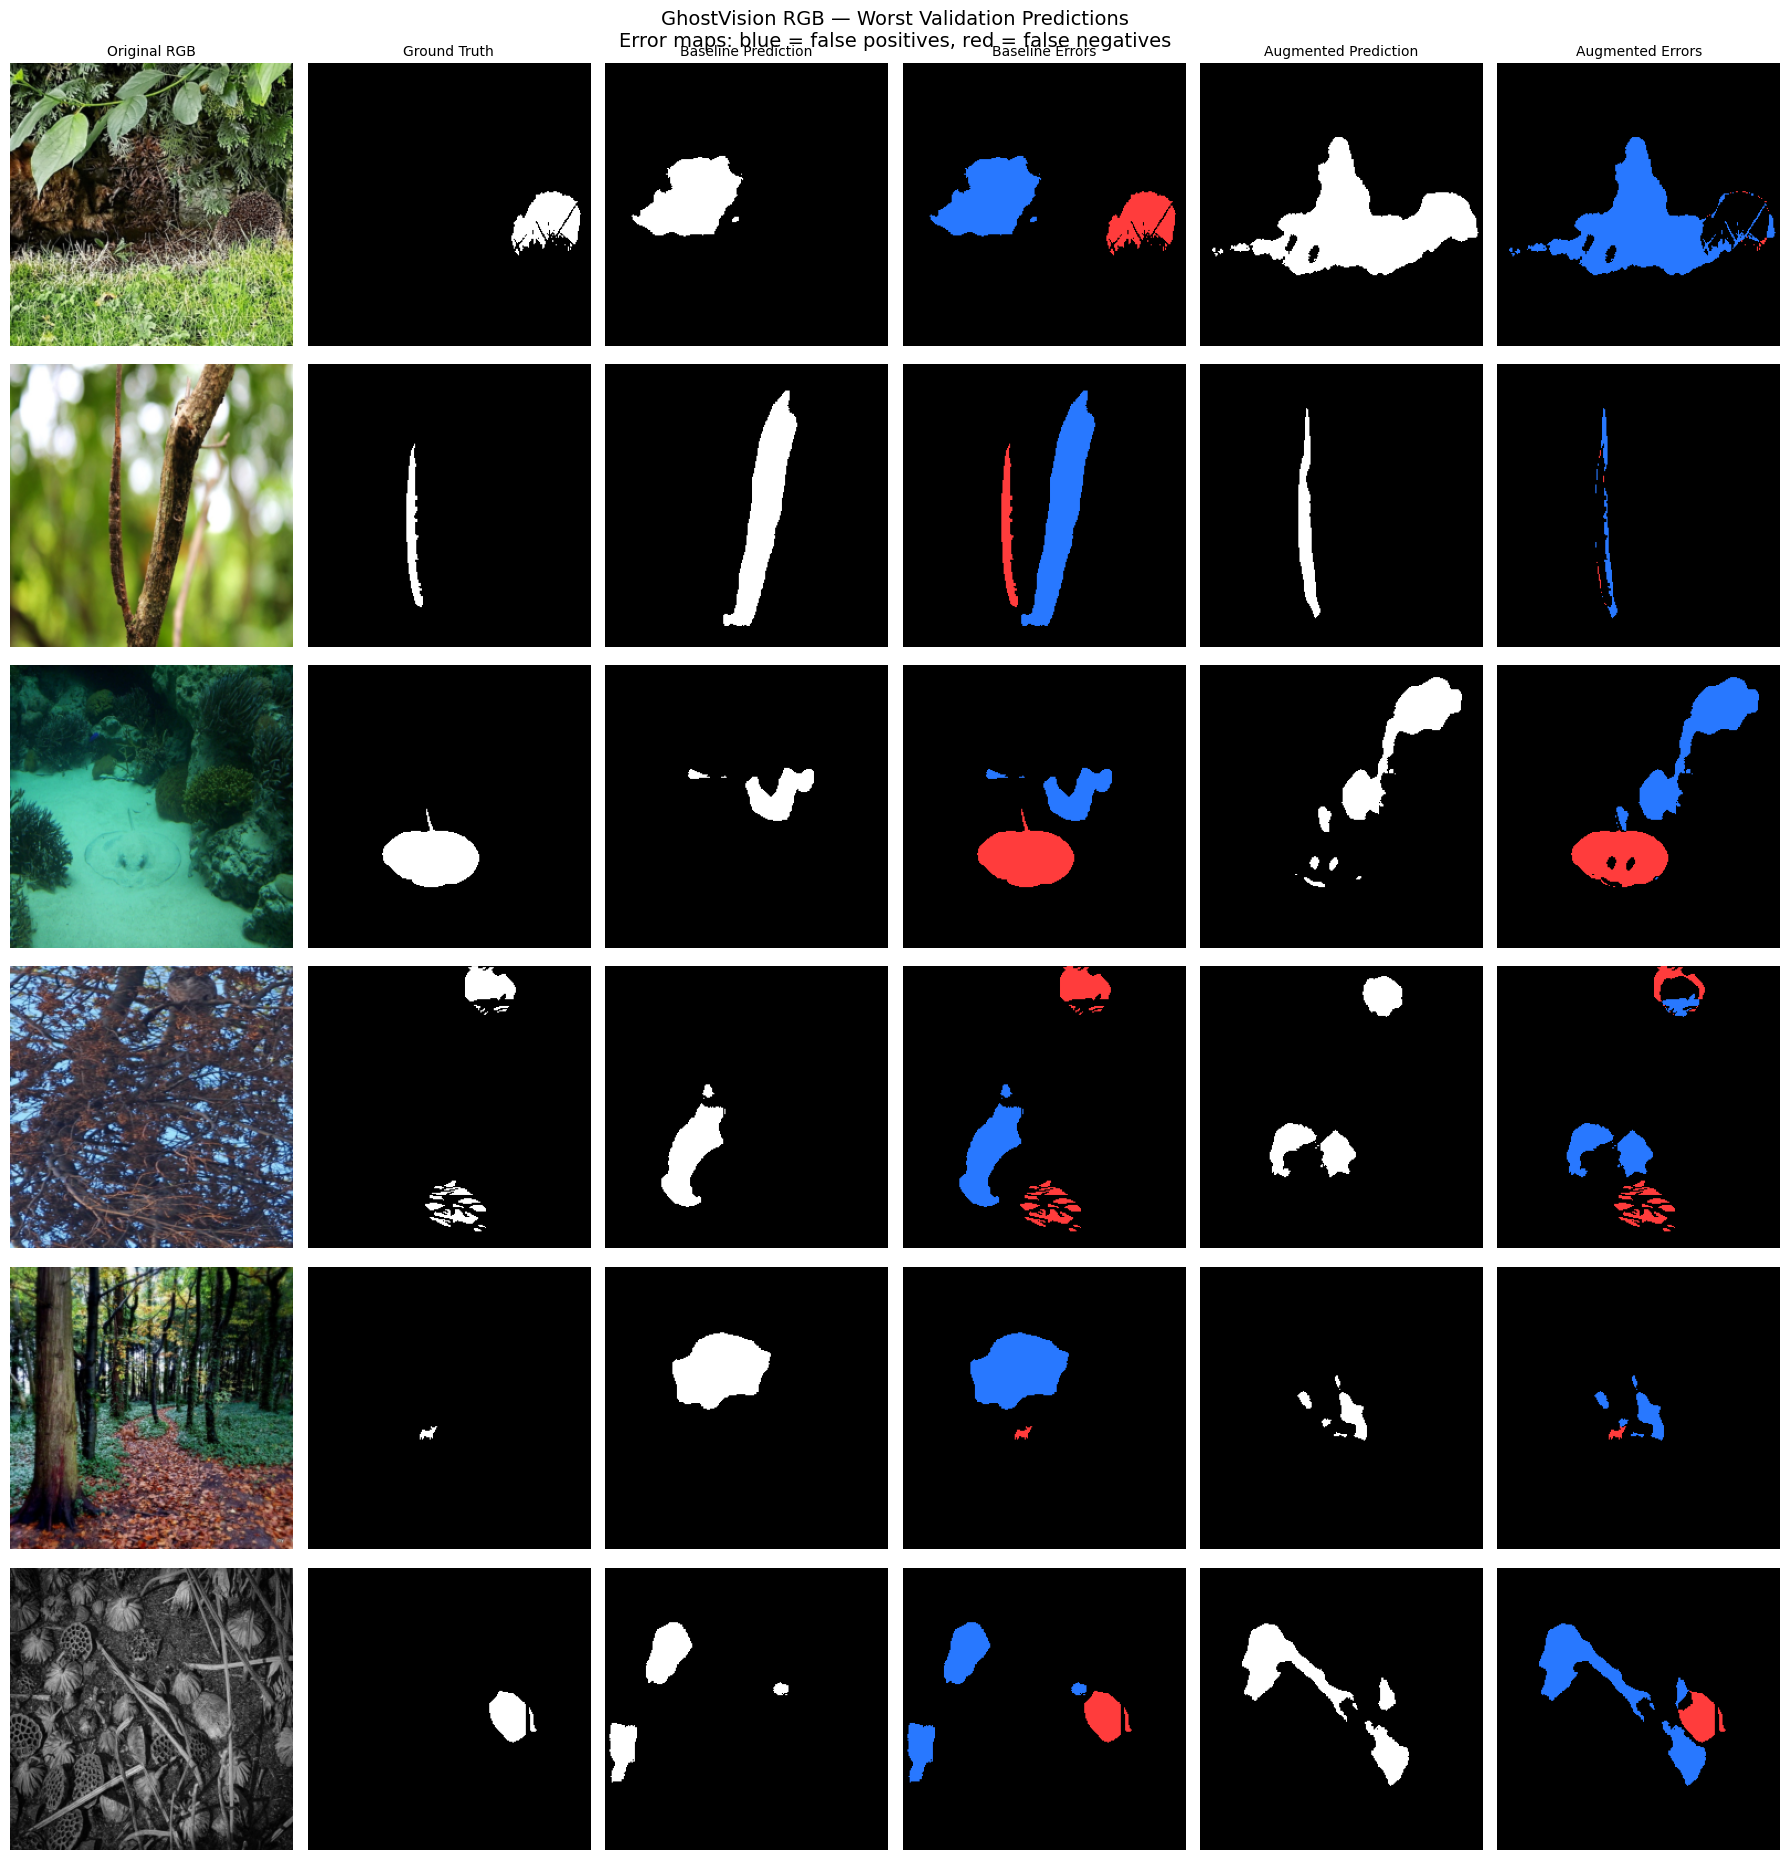


Saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Final_Evaluation/validation_error_analysis.png

Validation error analysis: COMPLETED
Training performed: NO
Held-out test set accessed: NO


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path

# Use the existing validation loader and restored models.
assert "val_loader" in globals(), "Run the preprocessing cell first."
assert "baseline_model" in globals(), "Run the model restoration cell."
assert "augmented_model" in globals(), "Run the model restoration cell."
assert len(val_loader.dataset) == 304

baseline_model.eval()
augmented_model.eval()

all_images = []
all_masks = []
baseline_preds = []
augmented_preds = []
baseline_dice = []
augmented_dice = []

def calculate_image_dice(pred, target):
    pred = pred[:, 0].reshape(pred.shape[0], -1).float()
    target = target[:, 0].reshape(target.shape[0], -1).float()

    intersection = (pred * target).sum(dim=1)

    return (
        (2 * intersection + 1e-7)
        / (pred.sum(dim=1) + target.sum(dim=1) + 1e-7)
    )

# Validation inference only: no training and no test-set access.
with torch.inference_mode():
    for batch_images, batch_masks in val_loader:
        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        base_pred = (
            torch.sigmoid(baseline_model(batch_images)) >= 0.5
        )
        aug_pred = (
            torch.sigmoid(augmented_model(batch_images)) >= 0.5
        )
        target = batch_masks >= 0.5

        baseline_dice.extend(
            calculate_image_dice(base_pred, target).cpu().tolist()
        )
        augmented_dice.extend(
            calculate_image_dice(aug_pred, target).cpu().tolist()
        )

        # Convert normalized RGB images back for display.
        display = (
            batch_images.detach().cpu()
            .permute(0, 2, 3, 1).numpy()
        )
        mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 1, 3)
        std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 1, 3)
        display = np.clip(display * std + mean, 0, 1)

        all_images.extend(
            (display * 255).round().astype(np.uint8)
        )
        all_masks.extend(
            target[:, 0].cpu().numpy().astype(np.uint8)
        )
        baseline_preds.extend(
            base_pred[:, 0].cpu().numpy().astype(np.uint8)
        )
        augmented_preds.extend(
            aug_pred[:, 0].cpu().numpy().astype(np.uint8)
        )

assert len(all_images) == 304
assert len(baseline_dice) == 304
assert len(augmented_dice) == 304

# Select the six lowest-Dice baseline validation samples.
worst_indices = np.argsort(baseline_dice)[:6]

print("===== GHOSTVISION VALIDATION ERROR ANALYSIS =====")
print("Validation images analyzed:", len(all_images))
print("Samples displayed:", len(worst_indices))
print("\nWorst baseline validation samples:")

for idx in worst_indices:
    print(
        f"Sample {idx:3d} | "
        f"Baseline Dice: {baseline_dice[idx]:.4f} | "
        f"Augmented Dice: {augmented_dice[idx]:.4f}"
    )

def error_map(target, prediction):
    # Blue = false positives; red = false negatives.
    result = np.zeros((*target.shape, 3), dtype=np.uint8)

    false_positive = (prediction == 1) & (target == 0)
    false_negative = (prediction == 0) & (target == 1)

    result[false_positive] = [40, 120, 255]
    result[false_negative] = [255, 60, 60]

    return result

titles = [
    "Original RGB",
    "Ground Truth",
    "Baseline Prediction",
    "Baseline Errors",
    "Augmented Prediction",
    "Augmented Errors"
]

fig, axes = plt.subplots(6, 6, figsize=(18, 19))

for row, idx in enumerate(worst_indices):
    gt = all_masks[idx]
    base = baseline_preds[idx]
    aug = augmented_preds[idx]

    panels = [
        (all_images[idx], None),
        (gt, "gray"),
        (base, "gray"),
        (error_map(gt, base), None),
        (aug, "gray"),
        (error_map(gt, aug), None)
    ]

    for col, (panel, cmap) in enumerate(panels):
        if cmap:
            axes[row, col].imshow(panel, cmap=cmap, vmin=0, vmax=1)
        else:
            axes[row, col].imshow(panel)

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(titles[col], fontsize=10)

    axes[row, 0].set_ylabel(
        f"Val #{idx}\n"
        f"Base: {baseline_dice[idx]:.3f}\n"
        f"Aug: {augmented_dice[idx]:.3f}",
        fontsize=9,
        labelpad=8
    )

fig.suptitle(
    "GhostVision RGB — Worst Validation Predictions\n"
    "Error maps: blue = false positives, red = false negatives",
    fontsize=14
)
fig.tight_layout()
plt.show()

# Save the analysis artifact if Google Drive is mounted.
output_dir = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)

if Path("/content/drive/MyDrive").exists():
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / "validation_error_analysis.png"
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    print("\nSaved:", output_path)

print("\nValidation error analysis: COMPLETED")
print("Training performed: NO")
print("Held-out test set accessed: NO")


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

base = np.asarray(baseline_dice, dtype=float)
aug = np.asarray(augmented_dice, dtype=float)

assert len(base) == len(aug) == 304
assert np.isfinite(base).all() and np.isfinite(aug).all()

delta = aug - base
epsilon = 1e-6

print("===== GHOSTVISION PAIRED VALIDATION ANALYSIS =====")
print("Validation samples:", len(base))
print(f"Baseline mean Dice:   {base.mean():.4f}")
print(f"Augmented mean Dice:  {aug.mean():.4f}")
print(f"Mean Dice difference: {delta.mean():+.4f}")
print(f"Median Dice difference: {np.median(delta):+.4f}")

print("\n===== SAMPLE-BY-SAMPLE OUTCOMES =====")
print("Augmented improved:", int((delta > epsilon).sum()))
print("Baseline improved:", int((delta < -epsilon).sum()))
print("Effectively tied:", int((np.abs(delta) <= epsilon).sum()))

print("\n===== ZERO-DICE COUNTS =====")
print("Baseline zero-Dice samples:", int((base <= epsilon).sum()))
print("Augmented zero-Dice samples:", int((aug <= epsilon).sum()))

df = pd.DataFrame({
    "validation_loader_index": np.arange(len(base)),
    "baseline_dice": base,
    "augmented_dice": aug,
    "dice_difference": delta
})

print("\n===== TEN LARGEST IMPROVEMENTS =====")
print(
    df.nlargest(10, "dice_difference")
      .round(4).to_string(index=False)
)

print("\n===== TEN LARGEST REGRESSIONS =====")
print(
    df.nsmallest(10, "dice_difference")
      .round(4).to_string(index=False)
)

output_dir = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)

if Path("/content/drive/MyDrive").exists():
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / "paired_validation_dice_analysis.csv"
    df.to_csv(output_path, index=False)
    print("\nSaved:", output_path)

print("\nPaired validation analysis: COMPLETED")
print("Training performed: NO")
print("Held-out test set accessed: NO")


===== GHOSTVISION PAIRED VALIDATION ANALYSIS =====
Validation samples: 304
Baseline mean Dice:   0.5641
Augmented mean Dice:  0.5447
Mean Dice difference: -0.0194
Median Dice difference: -0.0060

===== SAMPLE-BY-SAMPLE OUTCOMES =====
Augmented improved: 140
Baseline improved: 156
Effectively tied: 8

===== ZERO-DICE COUNTS =====
Baseline zero-Dice samples: 18
Augmented zero-Dice samples: 14

===== TEN LARGEST IMPROVEMENTS =====
 validation_loader_index  baseline_dice  augmented_dice  dice_difference
                     130         0.0000          0.7583           0.7583
                     107         0.2343          0.8842           0.6499
                     189         0.0000          0.6243           0.6243
                     123         0.2325          0.7428           0.5103
                     181         0.3630          0.8474           0.4844
                     287         0.3158          0.6641           0.3483
                       7         0.4129          0.7398  

===== LARGEST VALIDATION REGRESSIONS =====
Sample 3: Baseline Dice=0.8715, Augmented Dice=0.0051, Difference=-0.8663
  Foreground pixels (%): GT=4.45, Baseline=4.32, Augmented=3.27
Sample 198: Baseline Dice=0.8052, Augmented Dice=0.0150, Difference=-0.7902
  Foreground pixels (%): GT=4.62, Baseline=6.46, Augmented=4.52
Sample 180: Baseline Dice=0.8693, Augmented Dice=0.2058, Difference=-0.6635
  Foreground pixels (%): GT=9.32, Baseline=10.65, Augmented=5.74
Sample 178: Baseline Dice=0.6834, Augmented Dice=0.0853, Difference=-0.5982
  Foreground pixels (%): GT=1.57, Baseline=2.67, Augmented=9.13
Sample 122: Baseline Dice=0.6857, Augmented Dice=0.1236, Difference=-0.5621
  Foreground pixels (%): GT=10.48, Baseline=6.85, Augmented=0.71
Sample 76: Baseline Dice=0.6872, Augmented Dice=0.1308, Difference=-0.5563
  Foreground pixels (%): GT=5.16, Baseline=3.88, Augmented=0.37

Saved: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Final_Evaluation/largest_validation_regressions.png


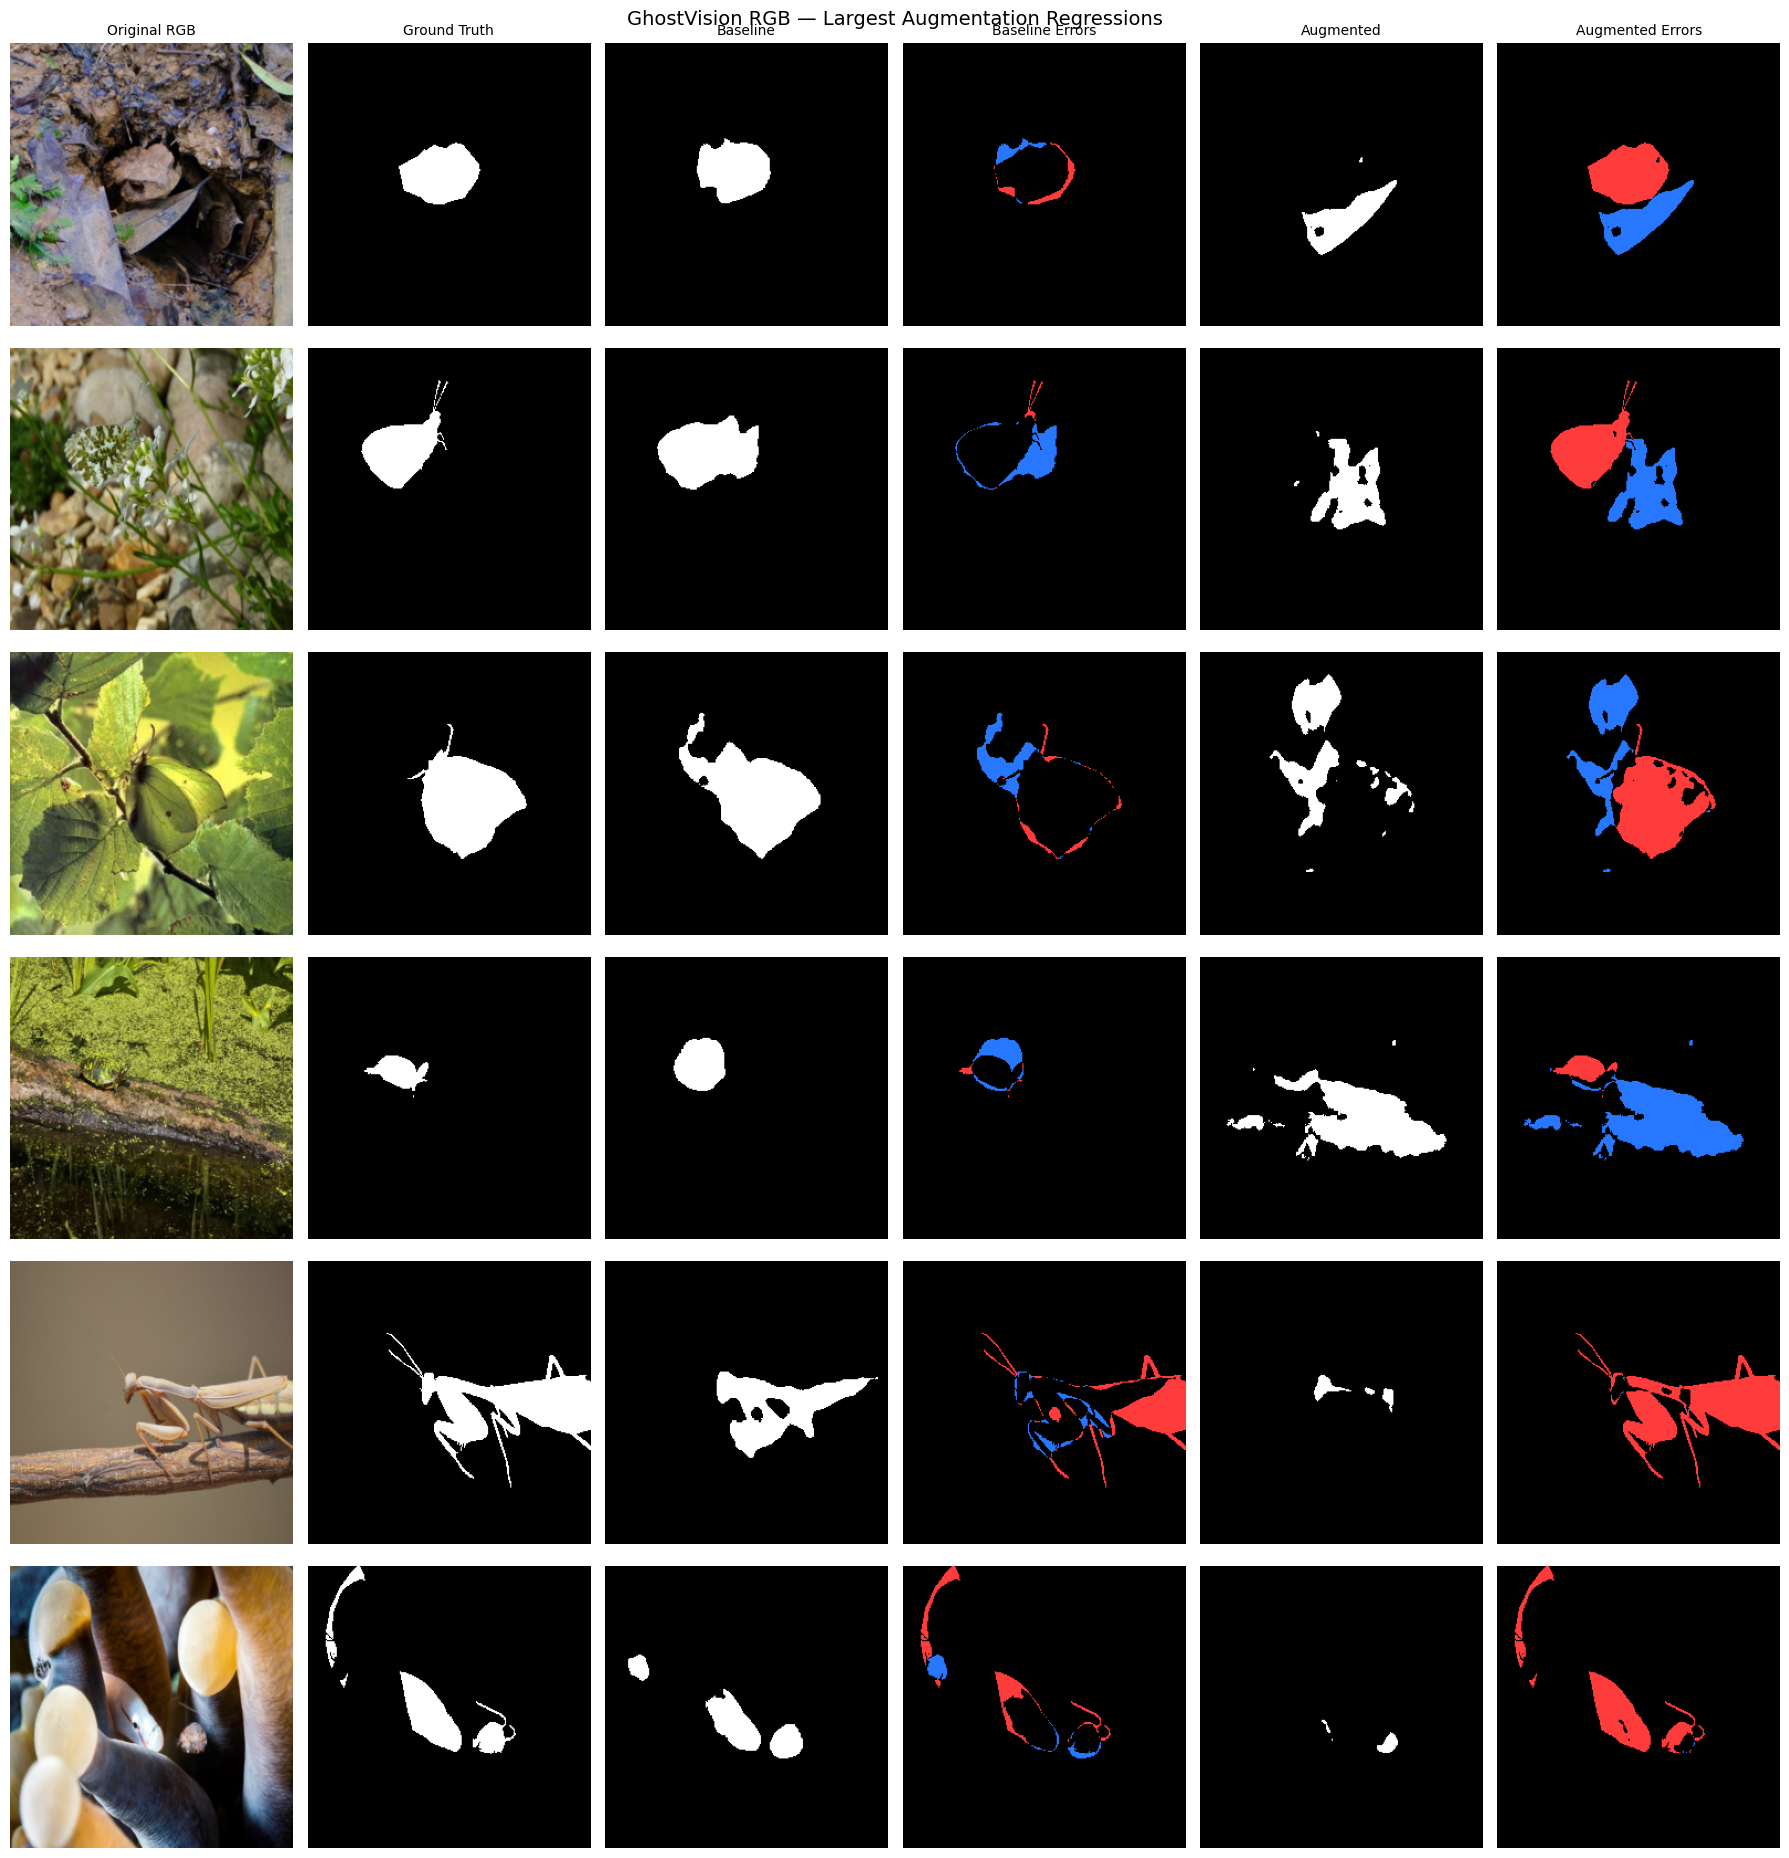


Regression visualization: COMPLETED
Training performed: NO
Held-out test set accessed: NO


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Identify the six largest regressions from paired validation results.
base = np.asarray(baseline_dice)
aug = np.asarray(augmented_dice)
delta = aug - base

worst_regressions = np.argsort(delta)[:6]

def make_error_map(target, prediction):
    result = np.zeros((*target.shape, 3), dtype=np.uint8)

    # Blue: false positives. Red: false negatives.
    result[(prediction == 1) & (target == 0)] = [40, 120, 255]
    result[(prediction == 0) & (target == 1)] = [255, 60, 60]

    return result

fig, axes = plt.subplots(6, 6, figsize=(18, 19))

titles = [
    "Original RGB",
    "Ground Truth",
    "Baseline",
    "Baseline Errors",
    "Augmented",
    "Augmented Errors"
]

print("===== LARGEST VALIDATION REGRESSIONS =====")

for row, idx in enumerate(worst_regressions):
    image = all_images[idx]
    target = all_masks[idx]
    base_pred = baseline_preds[idx]
    aug_pred = augmented_preds[idx]

    print(
        f"Sample {idx}: "
        f"Baseline Dice={base[idx]:.4f}, "
        f"Augmented Dice={aug[idx]:.4f}, "
        f"Difference={delta[idx]:+.4f}"
    )

    target_pct = 100 * target.mean()
    base_pct = 100 * base_pred.mean()
    aug_pct = 100 * aug_pred.mean()

    print(
        f"  Foreground pixels (%): "
        f"GT={target_pct:.2f}, "
        f"Baseline={base_pct:.2f}, "
        f"Augmented={aug_pct:.2f}"
    )

    panels = [
        (image, None),
        (target, "gray"),
        (base_pred, "gray"),
        (make_error_map(target, base_pred), None),
        (aug_pred, "gray"),
        (make_error_map(target, aug_pred), None)
    ]

    for col, (panel, cmap) in enumerate(panels):
        if cmap:
            axes[row, col].imshow(panel, cmap=cmap, vmin=0, vmax=1)
        else:
            axes[row, col].imshow(panel)

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(titles[col], fontsize=10)

    axes[row, 0].set_ylabel(
        f"Sample {idx}\n"
        f"Base {base[idx]:.3f}\n"
        f"Aug {aug[idx]:.3f}",
        fontsize=9
    )

fig.suptitle(
    "GhostVision RGB — Largest Augmentation Regressions",
    fontsize=14
)
fig.tight_layout()

output_dir = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)

if Path("/content/drive/MyDrive").exists():
    output_dir.mkdir(parents=True, exist_ok=True)
    save_path = output_dir / "largest_validation_regressions.png"
    fig.savefig(save_path, dpi=180, bbox_inches="tight")
    print("\nSaved:", save_path)

plt.show()

print("\nRegression visualization: COMPLETED")
print("Training performed: NO")
print("Held-out test set accessed: NO")


In [ ]:

import torch
from pathlib import Path
from pprint import pprint

checkpoints = {
    "BASELINE": Path(
        "/content/drive/MyDrive/GhostVision_AI/"
        "RGB_Checkpoints/best_rgb_unet_resnet34.pth"
    ),
    "AUGMENTED": Path(
        "/content/drive/MyDrive/GhostVision_AI/"
        "RGB_Checkpoints/Augmented_Experiment/"
        "best_augmented_unet.pth"
    ),
}

for name, path in checkpoints.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    if not path.exists():
        print("Checkpoint missing:", path)
        continue

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    print("Saved epoch:", checkpoint.get("epoch"))

    print("\nTraining metrics:")
    pprint(checkpoint.get("train_metrics", "Not recorded"))

    print("\nValidation metrics:")
    pprint(checkpoint.get("val_metrics", "Not recorded"))

print("\nHistory inspection complete.")
print("Training performed: NO")
print("Held-out test set accessed: NO")



=============== BASELINE ===============
Saved epoch: 3

Training metrics:
{'dice': 0.640606581467634,
 'iou': 0.5127124138917142,
 'loss': 0.5677089432352468}

Validation metrics:
{'dice': 0.5641250492710816,
 'iou': 0.442964211890572,
 'loss': 0.6650701510278803}

=============== AUGMENTED ===============
Saved epoch: 5

Training metrics:
{'dice': 0.5966762126537791,
 'iou': 0.47095746991404314,
 'loss': 0.621550348157074}

Validation metrics:
{'dice': 0.5447390306937067,
 'iou': 0.4283105805516243,
 'loss': 0.6855048772535826}

History inspection complete.
Training performed: NO
Held-out test set accessed: NO


## Safe RGB continuation: epochs 6–20

This section treats every epoch-1-to-5 checkpoint, history, plot, and evaluation result as read-only. Resumed artifacts use immutable per-epoch names under `RGB_Checkpoints/Resume_Epoch_06_20/Baseline` and `RGB_Checkpoints/Resume_Epoch_06_20/Augmented`; an existing destination causes a safe failure.

The epoch-5 files did not capture Python, NumPy, PyTorch CPU/CUDA, or DataLoader RNG state, and those states cannot be reconstructed. Epoch 6 uses a documented deterministic fallback seed. New resume checkpoints capture all available RNG states so a later interruption can resume reproducibly.

Run the read-only preflight before either opt-in training launcher.

In [ ]:
import json
import random
from pathlib import Path

import numpy as np
import torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader

RESUME_FIRST_EPOCH = 6
RESUME_FINAL_EPOCH = 20
RESUME_BATCH_SIZE = 8
RESUME_LR = 1e-4
RESUME_WEIGHT_DECAY = 1e-4

ORIGINAL_RGB_ROOT = Path(
    "/content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints"
)
RGB_RESUME_ROOT = ORIGINAL_RGB_ROOT / "Resume_Epoch_06_20"

RGB_RESUME_SPECS = {
    "baseline": {
        "label": "Baseline",
        "last": ORIGINAL_RGB_ROOT / "last_rgb_checkpoint.pth",
        "best": ORIGINAL_RGB_ROOT / "best_rgb_unet_resnet34.pth",
        "history": ORIGINAL_RGB_ROOT / "rgb_training_history.json",
        "output": RGB_RESUME_ROOT / "Baseline",
        "fallback_seed": 60042,
    },
    "augmented": {
        "label": "Augmented",
        "last": (
            ORIGINAL_RGB_ROOT / "Augmented_Experiment"
            / "last_augmented_unet.pth"
        ),
        "best": (
            ORIGINAL_RGB_ROOT / "Augmented_Experiment"
            / "best_augmented_unet.pth"
        ),
        "history": (
            ORIGINAL_RGB_ROOT / "Augmented_Experiment"
            / "augmented_history.json"
        ),
        "output": RGB_RESUME_ROOT / "Augmented",
        "fallback_seed": 60043,
    },
}
RESUME_HISTORY_KEYS = (
    "epoch", "train_loss", "train_dice", "train_iou",
    "val_loss", "val_dice", "val_iou",
)


def _read_history(path):
    with open(path, "r", encoding="utf-8") as handle:
        return json.load(handle)


def _check_history(history, epoch, label):
    missing = [key for key in RESUME_HISTORY_KEYS if key not in history]
    if missing:
        raise KeyError(f"{label} history missing keys: {missing}")
    if history["epoch"] != list(range(1, epoch + 1)):
        raise ValueError(
            f"{label} history must contain each epoch from 1 to {epoch}."
        )
    for key in RESUME_HISTORY_KEYS:
        if len(history[key]) != epoch:
            raise ValueError(
                f"{label} history {key} length is not {epoch}."
            )
    for key in RESUME_HISTORY_KEYS[1:]:
        if not np.isfinite(np.asarray(history[key], dtype=float)).all():
            raise ValueError(f"{label} history {key} is not finite.")


def _check_optimizer(state, label):
    if not state.get("state") or not state.get("param_groups"):
        raise ValueError(f"{label} AdamW optimizer state is incomplete.")
    for group in state["param_groups"]:
        if not np.isclose(group["lr"], RESUME_LR):
            raise ValueError(f"{label} learning rate is not {RESUME_LR}.")
        if not np.isclose(
            group["weight_decay"], RESUME_WEIGHT_DECAY
        ):
            raise ValueError(
                f"{label} weight decay is not {RESUME_WEIGHT_DECAY}."
            )


def _new_resume_model_optimizer():
    resume_model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None,
    )
    resume_optimizer = torch.optim.AdamW(
        resume_model.parameters(),
        lr=RESUME_LR,
        weight_decay=RESUME_WEIGHT_DECAY,
    )
    return resume_model, resume_optimizer


def _check_checkpoint(checkpoint, history, epoch, label, need_rng):
    required = {
        "epoch", "model_state_dict", "optimizer_state_dict",
        "train_metrics", "val_metrics", "architecture",
    }
    missing = sorted(required.difference(checkpoint))
    if missing:
        raise KeyError(f"{label} checkpoint missing keys: {missing}")
    if checkpoint["epoch"] != epoch:
        raise ValueError(
            f"{label} checkpoint is epoch {checkpoint['epoch']}, "
            f"not epoch {epoch}."
        )
    if checkpoint["architecture"] != "Unet-ResNet34":
        raise ValueError(f"{label} architecture does not match.")
    if not checkpoint["model_state_dict"]:
        raise ValueError(f"{label} model state is empty.")
    _check_optimizer(checkpoint["optimizer_state_dict"], label)
    _check_history(history, epoch, label)

    for metric in ("loss", "dice", "iou"):
        if not np.isclose(
            checkpoint["train_metrics"][metric],
            history[f"train_{metric}"][-1],
            rtol=0.0, atol=1e-12,
        ):
            raise ValueError(
                f"{label} train {metric} disagrees with history."
            )
        if not np.isclose(
            checkpoint["val_metrics"][metric],
            history[f"val_{metric}"][-1],
            rtol=0.0, atol=1e-12,
        ):
            raise ValueError(
                f"{label} validation {metric} disagrees with history."
            )
    if need_rng and "rng_state" not in checkpoint:
        raise KeyError(f"{label} resumed checkpoint has no RNG state.")


def _artifact_epoch(path, prefix):
    value = path.stem.removeprefix(prefix)
    if not value.isdigit():
        raise ValueError(f"Unexpected artifact name: {path.name}")
    return int(value)


def _resume_epochs(spec):
    output = spec["output"]
    if not output.exists():
        return []
    temporary = list(output.glob("*.tmp"))
    if temporary:
        raise RuntimeError(
            "Incomplete temporary files need review: "
            + ", ".join(path.name for path in temporary)
        )
    checkpoints = {
        _artifact_epoch(path, "checkpoint_epoch_")
        for path in output.glob("checkpoint_epoch_*.pth")
    }
    histories = {
        _artifact_epoch(path, "history_through_epoch_")
        for path in output.glob("history_through_epoch_*.json")
    }
    best = {
        _artifact_epoch(path, "best_resumed_epoch_")
        for path in output.glob("best_resumed_epoch_*.pth")
    }
    if checkpoints != histories or not best.issubset(checkpoints):
        raise RuntimeError(
            f"{spec['label']} resume artifacts are incomplete."
        )
    if checkpoints:
        expected = set(range(RESUME_FIRST_EPOCH, max(checkpoints) + 1))
        if checkpoints != expected or max(checkpoints) > RESUME_FINAL_EPOCH:
            raise RuntimeError(
                f"{spec['label']} resume epochs are not valid and contiguous."
            )
    return sorted(checkpoints)


def _history_prefix_matches(original, resumed, label):
    for key in RESUME_HISTORY_KEYS:
        prefix = resumed[key][:len(original[key])]
        if key == "epoch":
            matches = prefix == original[key]
        else:
            matches = np.allclose(
                prefix, original[key], rtol=0.0, atol=1e-12
            )
        if not matches:
            raise ValueError(
                f"{label} resumed history changed original {key}."
            )


def run_rgb_resume_preflight():
    results = {}
    for name, spec in RGB_RESUME_SPECS.items():
        label = spec["label"]
        required = (spec["last"], spec["best"], spec["history"])
        missing = [path for path in required if not path.is_file()]
        if missing:
            raise FileNotFoundError(
                f"{label} prerequisites missing: "
                + ", ".join(str(path) for path in missing)
            )

        original_history = _read_history(spec["history"])
        original_last = torch.load(
            spec["last"], map_location="cpu", weights_only=True
        )
        original_best = torch.load(
            spec["best"], map_location="cpu", weights_only=True
        )
        _check_checkpoint(
            original_last, original_history, 5, label, need_rng=False
        )
        prior_best = max(original_history["val_dice"])
        if original_best.get("architecture") != "Unet-ResNet34":
            raise ValueError(f"{label} best architecture differs.")
        if not np.isclose(
            original_best["val_metrics"]["dice"],
            prior_best, rtol=0.0, atol=1e-12,
        ):
            raise ValueError(
                f"{label} best checkpoint disagrees with history."
            )

        model_check, optimizer_check = _new_resume_model_optimizer()
        model_check.load_state_dict(
            original_last["model_state_dict"], strict=True
        )
        optimizer_check.load_state_dict(
            original_last["optimizer_state_dict"]
        )

        epochs = _resume_epochs(spec)
        source_epoch = epochs[-1] if epochs else 5
        source_kind = "resumed" if epochs else "original epoch-5"

        if epochs:
            checkpoint_path = (
                spec["output"]
                / f"checkpoint_epoch_{source_epoch:02d}.pth"
            )
            history_path = (
                spec["output"]
                / f"history_through_epoch_{source_epoch:02d}.json"
            )
            checkpoint = torch.load(
                checkpoint_path, map_location="cpu", weights_only=False
            )
            history = _read_history(history_path)
            _check_checkpoint(
                checkpoint, history, source_epoch, label, need_rng=True
            )
            _history_prefix_matches(
                original_history, history, label
            )
            model_check.load_state_dict(
                checkpoint["model_state_dict"], strict=True
            )
            optimizer_check.load_state_dict(
                checkpoint["optimizer_state_dict"]
            )
            best_index = int(np.argmax(history["val_dice"]))
            best_epoch = history["epoch"][best_index]
            if best_epoch >= RESUME_FIRST_EPOCH:
                best_path = (
                    spec["output"]
                    / f"best_resumed_epoch_{best_epoch:02d}.pth"
                )
                if not best_path.is_file():
                    raise FileNotFoundError(
                        f"{label} resumed best file is missing."
                    )

        results[name] = {
            "source_epoch": source_epoch,
            "next_epoch": source_epoch + 1,
            "source_kind": source_kind,
            "prior_best_val_dice": float(prior_best),
            "resume_epochs": epochs,
            "original_rng_state_available": (
                "rng_state" in original_last
            ),
        }
        del model_check, optimizer_check
        print(
            f"{label}: PASSED | source={source_kind} | "
            f"completed={source_epoch} | next={source_epoch + 1}"
        )

    print("Read-only preflight passed; no files were written.")
    print("Missing epoch-5 RNG states cannot be recovered.")
    return results


In [ ]:
# Read-only: this cell loads and validates but never writes.
RGB_RESUME_PREFLIGHT = run_rgb_resume_preflight()


### Opt-in continuation

The helpers below preserve U-Net/ResNet34, the COD10K split, 256×256 preprocessing, BCE-plus-Dice loss, AdamW at 0.0001 with weight decay 0.0001, batch size 8, and horizontal-plus-vertical flips for only the augmented training loader.

Each launcher defaults to disabled. Set its flag to `True` in a separate cell immediately before running that launcher. Approval is consumed before training. The workflow re-runs the read-only preflight, refuses any epoch below 6, and never replaces an existing resume artifact.

In [ ]:
import os
import uuid


RESUME_BCE_LOSS = torch.nn.BCEWithLogitsLoss()


def _resume_dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits).flatten(1)
    targets = targets.flatten(1)
    intersection = (probabilities * targets).sum(dim=1)
    total = probabilities.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * intersection + smooth) / (total + smooth)
    return 1 - dice.mean()


def _resume_combined_loss(logits, targets):
    return RESUME_BCE_LOSS(logits, targets) + _resume_dice_loss(
        logits, targets
    )


def _resume_metrics(logits, targets, eps=1e-7):
    predictions = (torch.sigmoid(logits) >= 0.5).float()
    intersection = (predictions * targets).sum(dim=(1, 2, 3))
    pred_sum = predictions.sum(dim=(1, 2, 3))
    target_sum = targets.sum(dim=(1, 2, 3))
    dice = (2 * intersection + eps) / (
        pred_sum + target_sum + eps
    )
    union = pred_sum + target_sum - intersection
    iou = (intersection + eps) / (union + eps)
    return dice.mean().item(), iou.mean().item()


def _check_resume_runtime(name):
    common = ("IMAGE_SIZE",)
    dataset_names = (
        ("train_data", "val_data")
        if name == "baseline"
        else ("aug_train_data", "aug_val_data")
    )
    missing = [
        variable for variable in common + dataset_names
        if variable not in globals()
    ]
    if missing:
        raise RuntimeError(
            "Run the non-training dataset and preprocessing "
            f"and metric setup cells first. Missing: {missing}"
        )
    if IMAGE_SIZE != 256:
        raise ValueError(f"IMAGE_SIZE changed to {IMAGE_SIZE}.")

    training_data = globals()[dataset_names[0]]
    validation_data = globals()[dataset_names[1]]
    if len(training_data) != 2736 or len(validation_data) != 304:
        raise ValueError(
            "Training/validation split differs from 2736/304."
        )
    if name == "augmented":
        if not training_data.augment or validation_data.augment:
            raise ValueError(
                "Augmentation must be enabled only for training."
            )


def _move_optimizer_to_device(optimizer, target_device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(target_device)


def _capture_resume_rng(loader_generator):
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": {
            "name": numpy_state[0],
            "state": torch.from_numpy(numpy_state[1].copy()),
            "position": int(numpy_state[2]),
            "has_gauss": int(numpy_state[3]),
            "cached": float(numpy_state[4]),
        },
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else []
        ),
        "dataloader": loader_generator.get_state(),
    }


def _restore_resume_rng(state, loader_generator):
    random.setstate(state["python"])
    numpy_state = state["numpy"]
    np.random.set_state((
        numpy_state["name"],
        numpy_state["state"].cpu().numpy().astype(np.uint32),
        numpy_state["position"],
        numpy_state["has_gauss"],
        numpy_state["cached"],
    ))
    torch.set_rng_state(state["torch_cpu"].cpu())
    if torch.cuda.is_available():
        if len(state["torch_cuda"]) != torch.cuda.device_count():
            raise ValueError("CUDA RNG-state count differs from runtime.")
        torch.cuda.set_rng_state_all(
            [value.cpu() for value in state["torch_cuda"]]
        )
    loader_generator.set_state(state["dataloader"].cpu())


def _seed_unrecoverable_epoch5_rng(seed, loader_generator):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    loader_generator.manual_seed(seed)


def _save_new_torch(value, destination):
    if destination.exists():
        raise FileExistsError(
            f"Refusing to replace existing file: {destination}"
        )
    temporary = destination.with_name(
        f"{destination.name}.{uuid.uuid4().hex}.tmp"
    )
    torch.save(value, temporary)
    if destination.exists():
        raise FileExistsError(
            f"Destination appeared during save: {destination}; "
            f"temporary file retained at {temporary}."
        )
    os.replace(temporary, destination)


def _save_new_json(value, destination):
    if destination.exists():
        raise FileExistsError(
            f"Refusing to replace existing file: {destination}"
        )
    temporary = destination.with_name(
        f"{destination.name}.{uuid.uuid4().hex}.tmp"
    )
    with open(temporary, "x", encoding="utf-8") as handle:
        json.dump(value, handle, indent=2)
    if destination.exists():
        raise FileExistsError(
            f"Destination appeared during save: {destination}; "
            f"temporary file retained at {temporary}."
        )
    os.replace(temporary, destination)


def _load_resume_source(name, preflight):
    spec = RGB_RESUME_SPECS[name]
    epoch = preflight[name]["source_epoch"]
    if epoch == 5:
        checkpoint = torch.load(
            spec["last"], map_location="cpu", weights_only=True
        )
        history = _read_history(spec["history"])
    else:
        checkpoint = torch.load(
            spec["output"] / f"checkpoint_epoch_{epoch:02d}.pth",
            map_location="cpu",
            weights_only=False,
        )
        history = _read_history(
            spec["output"]
            / f"history_through_epoch_{epoch:02d}.json"
        )
    _check_checkpoint(
        checkpoint, history, epoch, spec["label"],
        need_rng=(epoch >= RESUME_FIRST_EPOCH),
    )
    return checkpoint, history


def _resume_loaders(name, loader_generator):
    if name == "baseline":
        training_data, validation_data = train_data, val_data
    elif name == "augmented":
        training_data, validation_data = aug_train_data, aug_val_data
    else:
        raise ValueError(f"Unknown experiment: {name}")

    return (
        DataLoader(
            training_data,
            batch_size=RESUME_BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
            generator=loader_generator,
        ),
        DataLoader(
            validation_data,
            batch_size=RESUME_BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
        ),
    )


def _resume_epoch(model, optimizer, loader, device, training):
    model.train(training)
    totals = {"loss": 0.0, "dice": 0.0, "iou": 0.0}
    count = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = _resume_combined_loss(logits, masks)
            if training:
                loss.backward()
                optimizer.step()

        dice, iou = _resume_metrics(logits.detach(), masks)
        size = images.size(0)
        totals["loss"] += loss.item() * size
        totals["dice"] += dice * size
        totals["iou"] += iou * size
        count += size

    return {key: value / count for key, value in totals.items()}


def run_rgb_resume(name, allow_training=False):
    if allow_training is not True:
        raise PermissionError(
            "Training disabled: use the explicit opt-in launcher."
        )
    if name not in RGB_RESUME_SPECS:
        raise ValueError(f"Unknown experiment: {name}")

    _check_resume_runtime(name)

    # Revalidate immediately before the first possible write or batch.
    preflight = run_rgb_resume_preflight()
    spec = RGB_RESUME_SPECS[name]
    checkpoint, history = _load_resume_source(name, preflight)
    completed_epoch = int(checkpoint["epoch"])
    next_epoch = completed_epoch + 1

    if next_epoch < RESUME_FIRST_EPOCH:
        raise RuntimeError(
            f"Refusing to restart {spec['label']} at epoch {next_epoch}."
        )
    if next_epoch > RESUME_FINAL_EPOCH:
        print(f"{spec['label']} already completed epoch {completed_epoch}.")
        return {"completed_epoch": completed_epoch, "history": history}

    model, optimizer = _new_resume_model_optimizer()
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    model = model.to(device)
    _move_optimizer_to_device(optimizer, device)

    loader_generator = torch.Generator()
    if "rng_state" in checkpoint:
        _restore_resume_rng(checkpoint["rng_state"], loader_generator)
        print(
            f"{spec['label']}: restored RNG state from epoch "
            f"{completed_epoch}."
        )
    else:
        _seed_unrecoverable_epoch5_rng(
            spec["fallback_seed"], loader_generator
        )
        print(
            f"{spec['label']}: epoch-5 RNG state is unavailable. "
            f"Using fallback seed {spec['fallback_seed']} from epoch 6."
        )

    train_loader_resume, val_loader_resume = _resume_loaders(
        name, loader_generator
    )

    # First write: only after opt-in and successful validation.
    spec["output"].mkdir(parents=True, exist_ok=True)
    best_val_dice = max(history["val_dice"])

    for epoch in range(next_epoch, RESUME_FINAL_EPOCH + 1):
        checkpoint_path = (
            spec["output"] / f"checkpoint_epoch_{epoch:02d}.pth"
        )
        history_path = (
            spec["output"]
            / f"history_through_epoch_{epoch:02d}.json"
        )
        if checkpoint_path.exists() or history_path.exists():
            raise FileExistsError(
                f"Refusing to retrain or replace epoch {epoch}."
            )

        print(
            f"\n===== {spec['label'].upper()} "
            f"EPOCH {epoch}/{RESUME_FINAL_EPOCH} ====="
        )
        train_metrics = _resume_epoch(
            model, optimizer, train_loader_resume, device, True
        )
        val_metrics = _resume_epoch(
            model, optimizer, val_loader_resume, device, False
        )

        history["epoch"].append(epoch)
        for metric, value in train_metrics.items():
            history[f"train_{metric}"].append(float(value))
        for metric, value in val_metrics.items():
            history[f"val_{metric}"].append(float(value))

        new_best = val_metrics["dice"] > best_val_dice
        if new_best:
            best_val_dice = val_metrics["dice"]

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_metrics": train_metrics,
            "val_metrics": val_metrics,
            "architecture": "Unet-ResNet34",
            "image_size": 256,
            "seed": spec["fallback_seed"],
            "best_val_dice": float(best_val_dice),
            "resume_source_epoch": completed_epoch,
            "rng_state": _capture_resume_rng(loader_generator),
        }
        if name == "augmented":
            state["augmentation"] = "horizontal_vertical_flip"

        _save_new_torch(state, checkpoint_path)
        _save_new_json(history, history_path)

        if new_best:
            best_path = (
                spec["output"]
                / f"best_resumed_epoch_{epoch:02d}.pth"
            )
            _save_new_torch(state, best_path)

        print("Training:", train_metrics)
        print("Validation:", val_metrics)
        print("Saved:", checkpoint_path)
        print("Saved:", history_path)

    return {
        "completed_epoch": history["epoch"][-1],
        "best_val_dice": max(history["val_dice"]),
        "history": history,
        "resume_directory": str(spec["output"]),
    }


In [ ]:
RUN_BASELINE_RESUME_TRAINING = globals().get(
    "RUN_BASELINE_RESUME_TRAINING", False
)
if RUN_BASELINE_RESUME_TRAINING is not True:
    raise PermissionError(
        "Set RUN_BASELINE_RESUME_TRAINING = True in a separate "
        "cell immediately before running this launcher."
    )
RUN_BASELINE_RESUME_TRAINING = False
BASELINE_RESUME_RESULT = run_rgb_resume(
    "baseline", allow_training=True
)


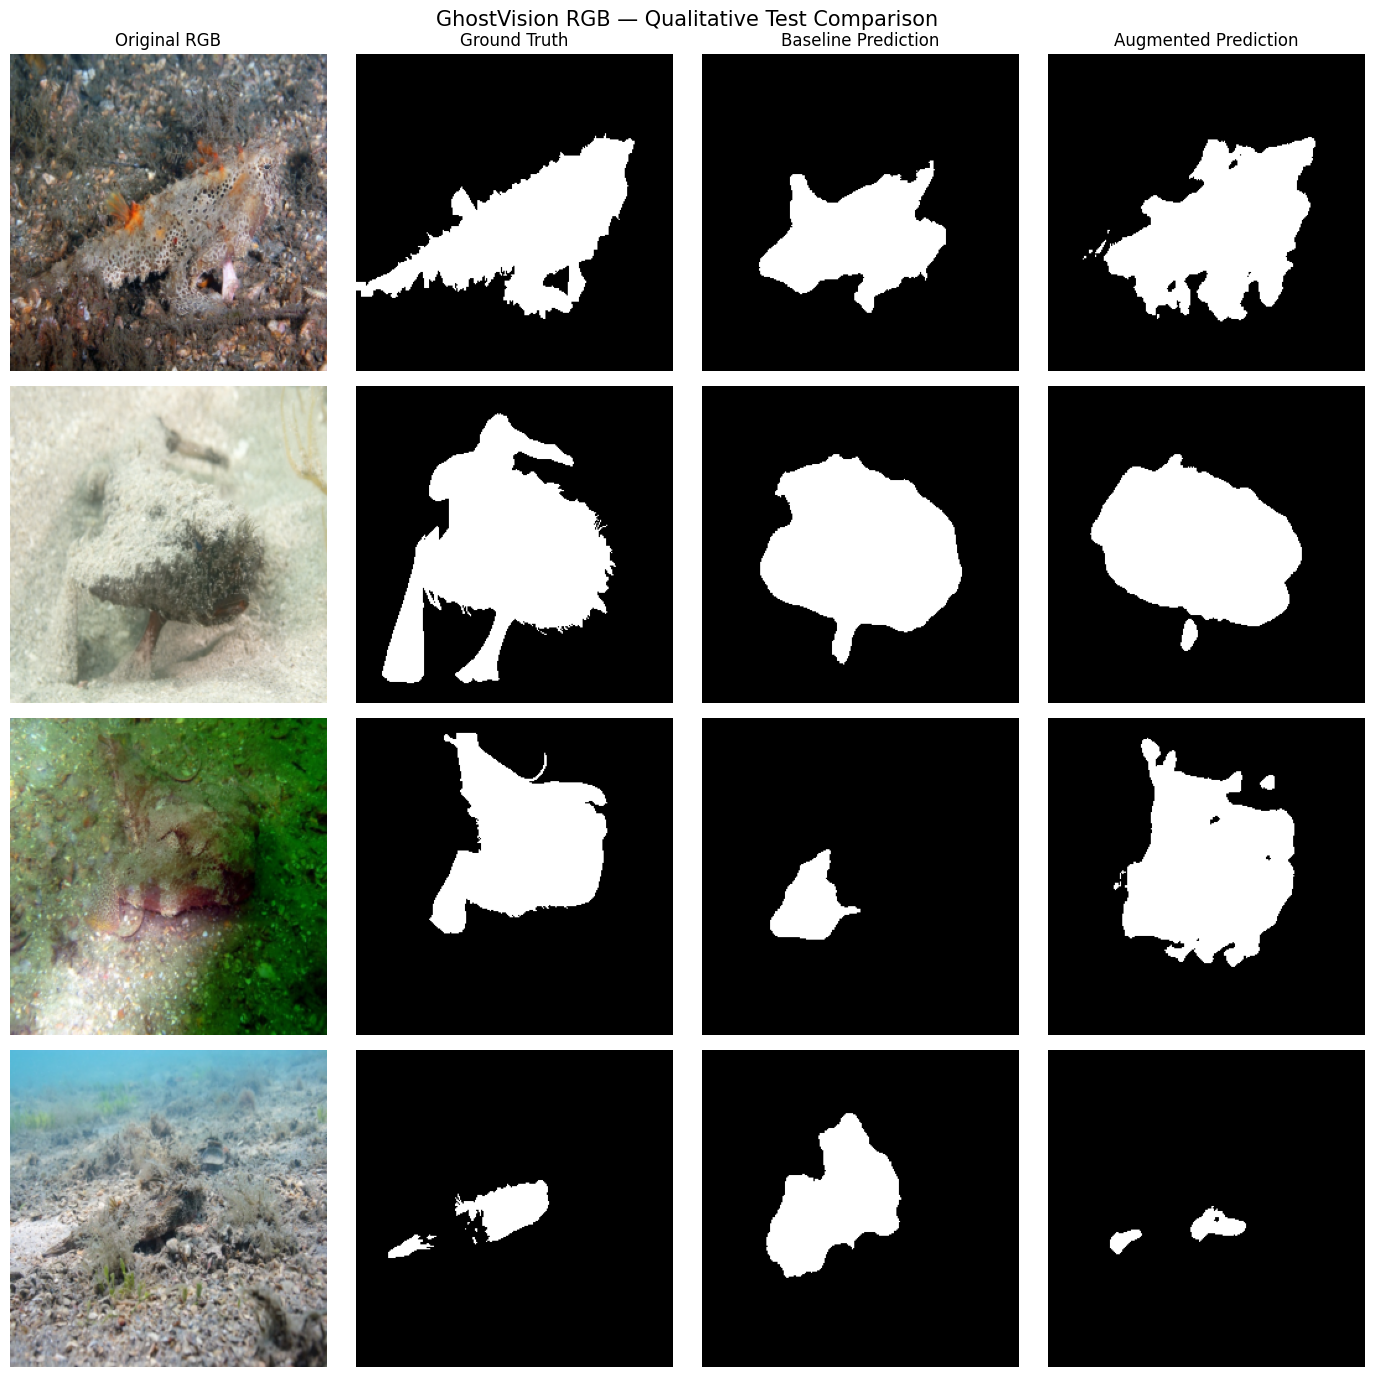

Visual comparison generated successfully.
Examples displayed: 4
Saved to: /content/drive/MyDrive/GhostVision_AI/RGB_Checkpoints/Final_Evaluation/qualitative_comparison.png
Training performed: NO


In [ ]:

import matplotlib.pyplot as plt
import torch
from pathlib import Path
import numpy as np

# Get a fresh batch from the held-out test set
test_images, test_masks = next(iter(test_loader))
test_images_device = test_images.to(device)

baseline_model.eval()
augmented_model.eval()

with torch.no_grad():
    baseline_probs = torch.sigmoid(
        baseline_model(test_images_device)
    ).cpu()

    augmented_probs = torch.sigmoid(
        augmented_model(test_images_device)
    ).cpu()

# Convert probability maps to binary masks
baseline_preds = (baseline_probs >= 0.5).float()
augmented_preds = (augmented_probs >= 0.5).float()

def image_for_display(tensor):
    image = tensor.detach().cpu().float().permute(1, 2, 0).numpy()

    # Undo ImageNet normalization if the tensor appears normalized
    if image.min() < -0.05 or image.max() > 1.05:
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        image = image * std + mean

    return np.clip(image, 0, 1)

num_samples = min(4, len(test_images))

fig, axes = plt.subplots(
    num_samples, 4, figsize=(14, 3.5 * num_samples)
)

if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

titles = [
    "Original RGB",
    "Ground Truth",
    "Baseline Prediction",
    "Augmented Prediction"
]

for row in range(num_samples):
    original = image_for_display(test_images[row])
    ground_truth = test_masks[row].squeeze().cpu().numpy()
    baseline_mask = baseline_preds[row, 0].numpy()
    augmented_mask = augmented_preds[row, 0].numpy()

    panels = [
        (original, None),
        (ground_truth, "gray"),
        (baseline_mask, "gray"),
        (augmented_mask, "gray")
    ]

    for col, (panel, cmap) in enumerate(panels):
        if cmap:
            axes[row, col].imshow(panel, cmap=cmap, vmin=0, vmax=1)
        else:
            axes[row, col].imshow(panel)

        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(titles[col])

fig.suptitle(
    "GhostVision RGB — Qualitative Test Comparison",
    fontsize=15
)
fig.tight_layout()

output_dir = Path(
    "/content/drive/MyDrive/GhostVision_AI/"
    "RGB_Checkpoints/Final_Evaluation"
)
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "qualitative_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Visual comparison generated successfully.")
print("Examples displayed:", num_samples)
print("Saved to:", figure_path)
print("Training performed: NO")


In [ ]:
RUN_AUGMENTED_RESUME_TRAINING = globals().get(
    "RUN_AUGMENTED_RESUME_TRAINING", False
)
if RUN_AUGMENTED_RESUME_TRAINING is not True:
    raise PermissionError(
        "Set RUN_AUGMENTED_RESUME_TRAINING = True in a separate "
        "cell immediately before running this launcher."
    )
RUN_AUGMENTED_RESUME_TRAINING = False
AUGMENTED_RESUME_RESULT = run_rgb_resume(
    "augmented", allow_training=True
)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
